# 🤝 Sistemas Multiagentes
### Inteligência Artificial — Ciência da Computação · Aula 10

<a href="https://colab.research.google.com/github/profluiscaparroz/inteligencia-artificial/blob/main/10-sistemas-multiagentes/10_Sistemas_Multiagentes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

**Objetivo desta aula:** Compreender os fundamentos dos Sistemas Multiagentes (SMA), suas arquiteturas, protocolos de comunicação e coordenação, além de implementações práticas de agentes autônomos que interagem para resolver problemas complexos.

---

### 🎯 Objetivos de aprendizagem

Ao final desta aula, você será capaz de:

1. **Definir** agente e sistema multiagente, e **diferenciar** um agente de um objeto ou de um programa comum;
2. **Descrever** um agente pelo modelo PEAS e **classificar** o ambiente em que ele atua;
3. **Comparar** arquiteturas de agentes (reativa, baseada em modelo, BDI, híbrida) e **medir** o efeito delas no desempenho;
4. **Explicar** como agentes se comunicam (atos de fala, FIPA ACL, JSON e protocolos atuais como MCP e A2A);
5. **Aplicar** mecanismos de alocação de tarefas e de mercado (Contract Net, leilões) a problemas reais, como apps de entrega e anúncios;
6. **Analisar** dilemas de cooperação com teoria dos jogos (Dilema do Prisioneiro, tragédia dos comuns, votação);
7. **Reconhecer** comportamento emergente (bandos, segregação, guerras de preço entre robôs) e por que ele é difícil de prever;
8. **Relacionar** os conceitos clássicos de SMA aos sistemas multiagente construídos com LLMs, incluindo seus riscos.

### 🗺️ Roteiro da aula

| Parte | Conteúdo | Destaques práticos |
|:-:|---|---|
| 0 | Preparação do ambiente | — |
| 1 | O que são SMA, agente × objeto, PEAS, tipos de ambiente, história | Onde você já usa SMA sem perceber |
| 2 | Arquiteturas de agentes | Robô aspirador reativo × com mapa 🎬; entregador BDI e o experimento ousado × cauteloso |
| 3 | Comunicação | A mesma conversa em FIPA ACL e em JSON; do Actor Model ao WhatsApp, MCP e A2A |
| 4 | Contract Net Protocol | Licitação de tarefas; app de entregas com lance por custo marginal |
| 5 | Leilões | Por que dizer a verdade no leilão de Vickrey; equivalência de receita 🎛️; anúncios do Google e pregão eletrônico |
| 6 | Coordenação e cooperação | Torneio de Axelrod 🎛️; o livro de US$ 23 milhões; tragédia dos comuns; Boids 🎬; Schelling 🎛️ |
| 7 | Decisão coletiva | Votação: maioria, dois turnos, Borda e Condorcet |
| 8 | SMA com LLMs | Orquestrador + especialistas num atendimento de e-commerce, com *guardrails* |
| 9–15 | Aplicações reais, ferramentas, comparações, resumo, exercícios e referências | Perguntas para discussão |

> 💡 **Como usar:** execute as células **em ordem**. 🎬 = animação (botão ▶), 🎛️ = controle interativo. Depois de **cada resultado** há uma seção **🔎 Como interpretar**.

---

## Parte 0 — Preparação do ambiente

Execute a célula abaixo antes das demais. Todas as simulações usam apenas `numpy`, `matplotlib` e `ipywidgets` (já instalados no Colab) e rodam sem internet.

In [22]:
# =====================================================
# IMPORTAÇÕES E FUNÇÕES AUXILIARES — execute primeiro
# =====================================================
import warnings
warnings.filterwarnings('ignore')

import json
import random
import itertools
from collections import deque, Counter
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import ipywidgets as widgets
from ipywidgets import interact

# Animações renderizadas como player HTML/JavaScript (funciona no Colab sem ffmpeg)
plt.rcParams['animation.html'] = 'jshtml'
plt.rcParams['animation.embed_limit'] = 60
plt.rcParams['figure.dpi'] = 90

CORES = {'azul': '#1f77b4', 'vermelho': '#d62728', 'verde': '#2ca02c', 'laranja': '#ff7f0e',
         'roxo': '#9467bd', 'cinza': '#bbbbbb', 'amarelo': '#ffd54f', 'marrom': '#8c564b'}


def mostrar_animacao(anim):
    # Exibe uma animação do matplotlib como player interativo (▶ ⏸ ⏭) e fecha a figura estática.
    plt.close(anim._fig)
    display(HTML(anim.to_jshtml()))


print('✅ Ambiente pronto!')


✅ Ambiente pronto!


#### 🔎 Como interpretar esta célula

- Carregamos `numpy` (contas vetorizadas), `matplotlib` (gráficos e animações), `ipywidgets` (controles interativos) e utilitários da biblioteca padrão (`random`, `itertools`, `collections`, `json`).
- `mostrar_animacao(anim)` exibe as animações como um **player** (▶ ⏸ ⏭). Use o avanço quadro a quadro para estudar cada passo.
- As simulações usam **sementes fixas** (`semente=...`, `default_rng(...)`): os números que você verá são os mesmos citados nos textos de interpretação. Mude a semente para ver outras execuções.

## 1. O que são Sistemas Multiagentes?

**Sistemas Multiagentes (SMA)**, ou Multi-Agent Systems (MAS), são sistemas compostos por múltiplos agentes inteligentes autônomos que interagem entre si para alcançar objetivos individuais ou coletivos.

Segundo **Wooldridge** (2009), um dos principais pesquisadores da área:

> *"Um sistema multiagente é aquele que consiste em um número de agentes que interagem uns com os outros, tipicamente trocando mensagens através de alguma infraestrutura de comunicação."*

E o que é um **agente**? Para **Russell e Norvig** (2020, cap. 2), agente é tudo o que **percebe** o ambiente por meio de **sensores** e **age** sobre ele por meio de **atuadores**. **Franklin e Graesser** (1996) acrescentam o tempo e a autonomia: um agente autônomo está **situado** em um ambiente, age sobre ele **ao longo do tempo** seguindo a **sua própria agenda** e, com isso, afeta o que vai perceber no futuro.

### 1.1 Características de Agentes

**Wooldridge e Jennings** (1995) propuseram a definição mais citada da área, a **noção fraca de agência**. Um **agente** possui as seguintes propriedades essenciais:

**Autonomia:** Opera sem intervenção direta de humanos ou outros agentes, controlando suas ações e estado interno.

**Reatividade:** Percebe ambiente e responde em tempo adequado às mudanças.

**Proatividade:** Toma iniciativa, exibindo comportamento direcionado a objetivos.

**Sociabilidade:** Interage com outros agentes (e possivelmente humanos) via linguagem de comunicação.

Na **noção forte de agência**, os mesmos autores descrevem o agente com conceitos "mentais" emprestados da psicologia: **crenças**, **desejos**, **intenções** e **obrigações**. É dessa visão que nasce a arquitetura BDI (Seção 2).

> 💡 **O difícil é equilibrar reatividade e proatividade.** Um agente só reativo "vai para onde o vento sopra" e nunca termina nada; um agente só proativo segue o plano mesmo quando o mundo mudou e o plano ficou sem sentido. Vamos medir esse equilíbrio no experimento do entregador (Seção 2.9).

### 1.2 Por que Sistemas Multiagentes?

SMA são adequados quando:

- **Distribuição natural do problema:** Múltiplas entidades com controle local
- **Conhecimento distribuído:** Informação dispersa geograficamente
- **Escalabilidade:** Sistema pode crescer adicionando agentes
- **Robustez:** Falha de um agente não colapsa sistema todo
- **Legado:** Integração de sistemas existentes
- **Paralelismo:** Múltiplos agentes executam simultaneamente
- **Interesses diferentes:** Os participantes pertencem a **donos diferentes** (empresas, pessoas) e cada um defende o seu interesse. Nenhum programa central pode simplesmente "mandar" em todos. Esse é o caso de mercados, leilões e apps de entrega, e é o motivo mais forte para pensar em agentes (Shoham e Leyton-Brown, 2009).

### 1.3 Agente × objeto × programa comum

Programadores costumam perguntar: "mas um agente não é só um objeto com métodos?". **Wooldridge** (2009) responde com um slogan: *"objetos fazem de graça; agentes fazem porque querem"*. A diferença está em **quem decide**:

| | **Objeto** (POO) | **Agente** |
|---|---|---|
| **Quem decide executar** | Quem chama o método. `estoque.reservar(item)` sempre executa | O próprio agente. Ele recebe um **pedido** e pode aceitar, recusar ou negociar |
| **Fluxo de controle** | Um só, controlado de fora | Cada agente tem o seu (laço *perceber → decidir → agir*) |
| **Comportamento** | Passivo: espera ser chamado | Proativo: toma iniciativa para cumprir objetivos |
| **Comunicação** | Chamada de método (sintaxe) | Mensagem com **intenção** (pedir, informar, propor, recusar) |
| **Interesses** | Os do programa que o contém | Podem ser **próprios** e até conflitar com os dos outros |

**Exemplo prático.** Em um *e-commerce*, a chamada `estoque.reservar("notebook", 1)` reserva o item e pronto. Já um **agente de estoque** que recebe o pedido "reserve 1 notebook" pode responder *"recuso: a última unidade está prometida a um cliente com pedido pago"* ou *"proponho: tenho o modelo superior pelo mesmo preço"*. A decisão pertence a ele, segundo as regras e objetivos dele.

> 🤔 **Para discutir:** um termostato é um agente? Pela definição mínima de Russell e Norvig, sim: ele percebe a temperatura e age ligando o aquecedor. Mas não tem proatividade nem sociabilidade. Por isso **Franklin e Graesser** (1996) propõem uma **taxonomia**: "ser agente" é uma questão de **grau**, não de sim ou não.

### 1.4 Descrevendo um agente: PEAS e os tipos de ambiente

**Russell e Norvig** (2020) sugerem descrever todo agente por quatro itens, o **PEAS**: medida de desempenho (*Performance*), ambiente (*Environment*), atuadores (*Actuators*) e sensores (*Sensors*). Veja agentes que você conhece:

| Agente | Medida de desempenho | Ambiente | Atuadores | Sensores |
|---|---|---|---|---|
| **Robô aspirador** | % do piso limpo, tempo, bateria gasta | Casa, móveis, pessoas, animais | Rodas, escovas, aspirador | Para-choque, sensor de sujeira, câmera, sensor de desnível |
| **Entregador de app** (humano ou robô) | Entregas no prazo, km rodados, avaliação | Cidade, trânsito, restaurantes, clientes | Moto, mensagens no app | GPS, notificações de pedidos |
| **Robô de preços de um vendedor** | Lucro, vendas, posição na busca | Marketplace, concorrentes, compradores | Alterar o preço | Preços dos concorrentes, vendas |
| **Robô de lances em anúncios** | Cliques e vendas por real gasto | Leilões de anúncios, outros anunciantes | Lance em cada leilão | Consulta do usuário, histórico de conversões |
| **Agente de atendimento com LLM** | Problemas resolvidos, satisfação, custo | Clientes, sistemas da empresa | Responder, chamar APIs (reembolso, rastreio) | Mensagens do cliente, respostas das APIs |
| **Carro autônomo** | Segurança, tempo de viagem, conforto | Ruas, outros veículos, pedestres | Volante, acelerador, freio, setas | Câmeras, LiDAR, radar, GPS |

O **ambiente** determina a dificuldade do projeto. Classifique-o pelas propriedades de Russell e Norvig:

| Propriedade | Mais fácil | Mais difícil | Exemplo prático |
|---|---|---|---|
| **Observabilidade** | Totalmente observável | Parcialmente observável | O aspirador não vê a casa toda; o robô de preços vê todos os preços públicos |
| **Número de agentes** | Agente único | **Multiagente** (cooperativo ou competitivo) | Xadrez contra o computador: competitivo. Robôs de um armazém: cooperativos |
| **Determinismo** | Determinístico | Estocástico | O trânsito é estocástico: o mesmo trajeto leva 15 ou 40 minutos |
| **Episódios** | Episódico (cada decisão isolada) | Sequencial (decisões afetam o futuro) | Classificar e-mails como spam é episódico; dirigir é sequencial |
| **Dinâmica** | Estático | **Dinâmico** (muda enquanto o agente pensa) | Pedidos surgem e são cancelados enquanto o entregador decide |
| **Estados** | Discreto | Contínuo | Jogo da velha é discreto; dirigir é contínuo |

> 💡 **A presença de outros agentes é o que torna um ambiente imprevisível de verdade:** eles também aprendem, se adaptam e às vezes tentam enganar você. Grande parte desta aula trata justamente disso.

### 1.5 Onde você já usa Sistemas Multiagentes (sem perceber)

| Situação do dia a dia | Quem são os agentes | Mecanismo de interação | Onde aparece na aula |
|---|---|---|---|
| Pedir comida ou uma corrida por aplicativo | Plataforma, entregadores/motoristas, restaurantes, clientes | Alocação de tarefas, preço dinâmico | Seção 4 (Contract Net aplicado a entregas) |
| Ver um anúncio ao pesquisar no Google | Robôs de lance de milhares de anunciantes | Leilão em tempo real, a cada busca (Edelman, Ostrovsky e Schwarz, 2007; Varian, 2007) | Seção 5 |
| Compras do governo (**pregão eletrônico**) | Empresas fornecedoras | Leilão reverso: vence o menor preço (Lei 10.520/2002 e Lei 14.133/2021) | Seção 5 |
| Preços que mudam sozinhos em marketplaces | Robôs de reprecificação de vendedores concorrentes | Reação ao preço do outro | Seção 6.5 |
| Waze e Google Maps no horário de pico | Milhões de motoristas, cada um buscando a sua rota | Escolhas egoístas que, somadas, podem piorar o trânsito de todos (paradoxo de Braess, 1968) | Seção 6 |
| Pacote saindo de um centro de distribuição da Amazon | Centenas de robôs móveis por armazém | Coordenação de tráfego e alocação de tarefas (Wurman, D'Andrea e Mountz, 2008) | Seção 9 |
| Internet funcionando sem congestionar | Cada computador que envia dados via TCP | Norma de cooperação: reduzir o envio quando há congestionamento (Jacobson, 1988) | Seção 6.6 |
| Assistentes de IA que fazem "pesquisa profunda" | Um agente orquestrador e vários subagentes com LLM | Divisão de tarefas e síntese de resultados | Seção 8 |
| Jogos com NPCs que agem em grupo | Personagens controlados por IA | Planejamento e coordenação de esquadrões (Orkin, 2006) | Seção 9 |

### 1.6 Breve História dos Sistemas Multiagentes

- **1973 — Carl Hewitt, Peter Bishop e Richard Steiger:** propõem o **Actor Model**, formalismo em que atores (agentes primitivos) só se comunicam por mensagens. É o ancestral de linguagens como **Erlang** e de bibliotecas como **Akka** (Seção 3.4).

- **Anos 1970 — Hearsay-II (Erman et al., 1980):** sistema de reconhecimento de fala em que vários "especialistas" cooperam escrevendo num **quadro-negro** (*blackboard*) compartilhado.

- **1980 — Contract Net Protocol:** **Reid G. Smith** publica o protocolo clássico de negociação e alocação de tarefas entre agentes (Seção 4).

- **1980–1984 — Robert Axelrod:** organiza os torneios de computador do **Dilema do Prisioneiro**; o "Olho por olho" de Anatol Rapoport vence os dois (Seção 6.4).

- **Anos 1980 — Inteligência Artificial Distribuída (DAI):** pesquisadores como Victor Lesser e Edmund Durfee estudam a resolução distribuída de problemas e a coordenação.

- **1986 — Rodney Brooks:** propõe a **arquitetura de subsunção**: robôs inteligentes **sem** modelo simbólico do mundo. Em 1990 cofunda a iRobot, que lança o aspirador **Roomba** em 2002 (Seção 2).

- **1987 — Craig Reynolds:** cria os **Boids**, bandos de pássaros virtuais com regras locais (Seção 6.7). No mesmo ano, o filósofo **Michael Bratman** publica a teoria das intenções que inspira a arquitetura BDI.

- **1990–1991 — BDI:** Pollack e Ringuette criam o **Tileworld**, ambiente de testes para agentes; Rao e Georgeff formalizam a arquitetura **BDI**; Kinny e Georgeff medem o efeito do "grau de compromisso" (Seção 2.9).

- **1994 — KQML:** Finin, Fritzson, McKay e McEntire propõem uma das primeiras linguagens de comunicação entre agentes.

- **1996 — FIPA (Foundation for Intelligent Physical Agents):** organização internacional fundada para padronizar a comunicação entre agentes. A especificação da **FIPA ACL** é consolidada em 2002.

- **1997 — RoboCup:** Kitano e colegas lançam a competição de futebol de robôs, um desafio de **coordenação multiagente em tempo real**. Equipes brasileiras participam com destaque até hoje.

- **1999 — Remote Agent (NASA):** um agente autônomo controla a sonda **Deep Space 1** no espaço (Muscettola et al., 1998).

- **1999–2000 — JADE (Java Agent DEvelopment Framework):** plataforma open-source que implementa os padrões FIPA e é amplamente adotada.

- **2002 — AAMAS:** primeira edição da conferência que se tornaria a principal da área.

- **2007 — Jason:** Bordini, Hübner e Wooldridge publicam o interpretador da linguagem BDI **AgentSpeak**, com forte participação de pesquisadores brasileiros.

- **2000s — Mercados Eletrônicos:** Uso de agentes em leilões, comércio eletrônico, publicidade on-line e sistemas de recomendação.

- **2008–2012 — Robôs de armazém:** a Kiva Systems coordena centenas de robôs por armazém (Wurman et al., 2008); a Amazon compra a empresa em 2012.

- **2010s — Internet das Coisas (IoT) e aprendizado por reforço multiagente:** SMA aplicados a redes de dispositivos inteligentes; em 2019, AlphaStar (DeepMind) e OpenAI Five atingem nível de elite em StarCraft II e Dota 2.

- **2023 — Agentes com LLMs:** *Generative Agents* (Park et al.) simula uma vila com 25 personagens movidos por LLM; surgem frameworks como AutoGen, CAMEL e MetaGPT (Seção 8).

- **2024–2025 — Protocolos para agentes de IA:** a Anthropic lança o **MCP** (*Model Context Protocol*, agente ↔ ferramentas) e o Google o **A2A** (*Agent2Agent*, agente ↔ agente), retomando, com JSON e HTTP, ideias da FIPA (Seção 3.4).

- **Atualidade — Aplicações diversas:** Veículos autônomos, smart grids, robótica de enxame, jogos, simulação social, assistentes de IA com vários agentes.

## 2. Arquiteturas de Agentes

A **arquitetura** é o "esqueleto" interno do agente: como ele transforma percepções em ações. Os quatro primeiros tipos abaixo seguem **Russell e Norvig** (2020, cap. 2); os demais são as arquiteturas clássicas da literatura de SMA (Wooldridge, 2009, caps. 3–5).

### 2.1 Agente Reativo Simples

Responde diretamente a percepções do ambiente com regras condição-ação.

```
se percepção = X então ação = Y
```

**Vantagens:** Simples, rápido.
**Desvantagens:** Sem memória, não lida bem com ambientes parcialmente observáveis.

**Exemplo prático:** o controle de estabilidade de um carro (se a roda patina, freia aquela roda) e os primeiros aspiradores robôs.

### 2.2 Agente Baseado em Modelo

Mantém estado interno (modelo do mundo) para lidar com observabilidade parcial.

**Exemplo prático:** um aspirador com mapa da casa sabe quais cômodos já limpou, mesmo sem enxergá-los agora (Seção 2.8).

### 2.3 Agente Baseado em Objetivos

Usa objetivos para guiar decisões, pode planejar sequências de ações.

**Exemplo prático:** o GPS que planeja a rota até o destino (busca, Aulas 03 e 04).

### 2.4 Agente Baseado em Utilidade

Maximiza função de utilidade, lida com trade-offs e incerteza.

**Exemplo prático:** o app que escolhe entre a rota mais rápida, a mais barata (sem pedágio) e a mais segura, ponderando cada critério.

### 2.5 Agente BDI (Beliefs-Desires-Intentions)

Arquitetura inspirada em filosofia da ação humana, especialmente na teoria do **raciocínio prático** de **Michael Bratman** (1987), formalizada por **Rao e Georgeff** (1991, 1995):

- **Beliefs (Crenças):** Conhecimento sobre o mundo (que pode estar **desatualizado** ou **errado**)
- **Desires (Desejos):** Objetivos que o agente quer alcançar (podem ser muitos e até conflitantes)
- **Intentions (Intenções):** Planos que o agente se comprometeu a executar

A ideia central de Bratman é que **intenções são compromissos**: depois de decidir, você não reavalia tudo a cada segundo. Isso economiza raciocínio, mas cria o risco de insistir em um plano que já não faz sentido. Na Seção 2.9 vamos medir esse dilema.

### 2.6 Arquitetura de Subsunção (Brooks)

**Rodney Brooks** (1986, 1991) criticou a IA simbólica dos anos 1980: robôs que montavam um modelo completo do mundo antes de agir eram lentos e frágeis. Sua proposta, a **subsunção**, organiza o agente em **camadas de comportamentos simples**, todas ligadas direto aos sensores. As camadas de **baixo** (como desviar de obstáculos) têm **prioridade** e podem suprimir as de cima (como explorar). Não há modelo do mundo: para Brooks, *"o mundo é o seu melhor modelo"* (Brooks, 1990).

**Na prática:** Brooks cofundou a iRobot, e o **Roomba** original seguia exatamente essa filosofia: regras simples em camadas, sem mapa. Gerações posteriores passaram a construir mapas da casa com câmera (vSLAM). Vamos comparar as duas abordagens na Seção 2.8.

### 2.7 Arquiteturas Híbridas

Combinam uma camada **reativa** (rápida) com uma **deliberativa** (planejamento) e, às vezes, uma camada **social** (cooperação com outros agentes). Exemplos clássicos: **TouringMachines** (Ferguson, 1992) e **InteRRaP** (Müller, 1996).

**Exemplo prático, carro autônomo:** a camada reativa faz a frenagem de emergência em milissegundos; a deliberativa planeja a rota e as mudanças de faixa; a social negocia a passagem em cruzamentos com outros veículos (Dresner e Stone, 2008).

### 2.8 🧪 Na prática: robô aspirador reativo × robô com mapa

Vamos colocar **dois robôs aspiradores** na mesma casa (paredes e móveis em preto), com o piso inteiro sujo:

| | **Reativo (subsunção)** | **Baseado em modelo** |
|---|---|---|
| **Sensores** | "Chão sujo aqui?" e "bati à frente?" | Os mesmos, mais um sensor de proximidade nas 4 direções |
| **Memória** | Nenhuma | Mapa interno: células visitadas e obstáculos conhecidos |
| **Regras** | Camada 1: se sujo, aspira · Camada 2: se bateu, gira · Camada 3: às vezes, muda de rumo · Camada 4: segue em frente | Se sujo, aspira; senão, vai para a célula **ainda não visitada** mais próxima (busca em largura no mapa interno, Aula 03) |
| **Inspiração** | Roomba original (Brooks, 1986) | Robôs com mapeamento (vSLAM) |

Cada passo é **uma** ação: andar, girar ou aspirar.

Piso a limpar: 80 células

Agente                       limpo em 100 passos   em 200   em 400    90% em
Reativo (média de 30 robôs)                  33%      48%      69%    não chegou
Com modelo (mapa interno)                    61%     100%     100%    146 passos

Pior robô reativo em 400 passos: 44% · melhor: 85%


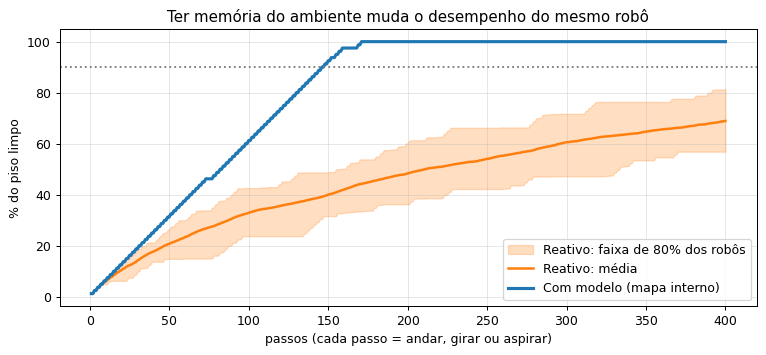

In [23]:
# 🤖 Robô aspirador: agente REATIVO (camadas, à la Brooks) × agente BASEADO EM MODELO (com mapa na memória)
PLANTA = ['##############',
          '#............#',
          '#..###.......#',
          '#..###...##..#',
          '#........##..#',
          '#............#',
          '#.....#......#',
          '#.....#...####',
          '#.....#......#',
          '##############']
MAPA = np.array([[c == '#' for c in linha] for linha in PLANTA])   # True = parede ou móvel
N_PISO = int((~MAPA).sum())
DIRECOES = [(-1, 0), (0, 1), (1, 0), (0, -1)]                       # N, L, S, O
BASE = (1, 1)


class AspiradorReativo:
    # Sem memória: só percebe "o chão aqui está sujo?" e "bati em algo à frente?".
    # Regras em camadas: a de cima tem prioridade sobre as de baixo (arquitetura de subsunção).
    def __init__(self, semente=0):
        self.pos, self.dir = BASE, 1
        self.rng = random.Random(semente)

    def agir(self, sujeira):
        i, j = self.pos
        if sujeira[i, j]:                               # camada 1: chão sujo -> aspirar
            sujeira[i, j] = False
            return 'aspirar'
        di, dj = DIRECOES[self.dir]
        if MAPA[i + di, j + dj]:                        # camada 2: obstáculo -> girar para um lado qualquer
            self.dir = self.rng.randrange(4)
            return 'girar'
        if self.rng.random() < 0.1:                     # camada 3: de vez em quando muda de rumo (vagar)
            self.dir = self.rng.randrange(4)
            return 'girar'
        self.pos = (i + di, j + dj)                     # camada 4: seguir em frente
        return 'andar'


class AspiradorComModelo:
    # Mantém um MODELO do mundo: células já visitadas e obstáculos já percebidos.
    # Decide indo sempre para a célula ainda não visitada mais próxima (busca em largura no mapa interno).
    def __init__(self):
        self.pos = BASE
        self.visitadas = {BASE}
        self.paredes = set()

    def perceber(self):
        i, j = self.pos
        for di, dj in DIRECOES:                         # sensor de proximidade nas 4 direções
            if MAPA[i + di, j + dj]:
                self.paredes.add((i + di, j + dj))

    def proximo_passo(self):
        anterior, fila = {self.pos: None}, deque([self.pos])
        while fila:
            c = fila.popleft()
            if c not in self.visitadas:                 # achou a fronteira do mapa conhecido
                while anterior[c] != self.pos:
                    c = anterior[c]
                return c
            for di, dj in DIRECOES:
                v = (c[0] + di, c[1] + dj)
                if v not in anterior and v not in self.paredes:
                    anterior[v] = c
                    fila.append(v)
        return None                                     # não há mais nada a explorar

    def agir(self, sujeira):
        self.perceber()
        i, j = self.pos
        if sujeira[i, j]:
            sujeira[i, j] = False
            return 'aspirar'
        passo = self.proximo_passo()
        if passo is None:
            return 'voltar à base'
        self.pos = passo
        self.visitadas.add(passo)
        return 'andar'


def simular_aspirador(agente, passos=400):
    sujeira = ~MAPA                                     # todo o piso começa sujo
    limpo, quadros = [], []
    for t in range(passos):
        agente.agir(sujeira)
        limpo.append(100 * (1 - sujeira.sum() / N_PISO))
        if t % 8 == 0:
            quadros.append((sujeira.copy(), agente.pos))
    return np.array(limpo), quadros


curvas_reativo = np.array([simular_aspirador(AspiradorReativo(s))[0] for s in range(30)])
curva_modelo, quadros_modelo = simular_aspirador(AspiradorComModelo())
_, quadros_reativo = simular_aspirador(AspiradorReativo(0))

def primeiro_instante(curva, meta):
    idx = np.argmax(curva >= meta)
    return idx + 1 if curva[idx] >= meta else None

print(f'Piso a limpar: {N_PISO} células\n')
print(f'{"Agente":<28}{"limpo em 100 passos":>20}{"em 200":>9}{"em 400":>9}{"90% em":>10}')
media = curvas_reativo.mean(axis=0)
for nome, c in [('Reativo (média de 30 robôs)', media), ('Com modelo (mapa interno)', curva_modelo)]:
    t90 = primeiro_instante(c, 90)
    print(f'{nome:<28}{c[99]:>19.0f}%{c[199]:>8.0f}%{c[399]:>8.0f}%{(str(t90) + " passos") if t90 else "não chegou":>14}')
print(f'\nPior robô reativo em 400 passos: {curvas_reativo[:, -1].min():.0f}% · melhor: {curvas_reativo[:, -1].max():.0f}%')

fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(range(1, 401), np.percentile(curvas_reativo, 10, axis=0), np.percentile(curvas_reativo, 90, axis=0),
                color=CORES['laranja'], alpha=0.25, label='Reativo: faixa de 80% dos robôs')
ax.plot(range(1, 401), media, color=CORES['laranja'], lw=2, label='Reativo: média')
ax.plot(range(1, 401), curva_modelo, color=CORES['azul'], lw=2.5, label='Com modelo (mapa interno)')
ax.axhline(90, ls=':', color='gray')
ax.set_xlabel('passos (cada passo = andar, girar ou aspirar)'); ax.set_ylabel('% do piso limpo')
ax.set_title('Ter memória do ambiente muda o desempenho do mesmo robô')
ax.legend(loc='lower right'); ax.grid(alpha=0.3)
plt.show()


#### 🔎 Como interpretar o resultado

- **O robô com modelo limpa 100% do piso em cerca de 170 passos** (90% no passo 146). Como cada célula exige ao menos 2 ações (chegar e aspirar), o mínimo para as 80 células seria cerca de 160 passos: ele está perto do ideal, porque **não repassa por lugares já limpos**, exceto quando precisa voltar de um "beco" (os degraus da curva azul).
- **O robô reativo, em média, limpou só 69% em 400 passos** e **nenhum** dos 30 robôs chegou a 90%. Ele passa várias vezes pelos mesmos lugares e demora a "achar" os cantos atrás dos móveis.
- **A faixa laranja é larga** (de 44% a 85% no fim): o desempenho do reativo depende da **sorte**. Isso é típico de comportamentos aleatórios: são robustos, mas imprevisíveis.
- **Por que, então, alguém faria um robô reativo?** Ele é **barato** (sensores simples, nenhum processamento pesado), **robusto** (não há mapa para ficar errado se alguém muda um móvel de lugar) e, com tempo suficiente, cobre quase tudo. O Roomba original vendeu milhões de unidades assim. O robô com mapa precisa de câmera, processador e algoritmos de localização, e o mapa pode ficar **desatualizado**.
- **Lição de projeto:** a arquitetura certa depende do custo, do tempo disponível e de quanto o ambiente muda. Não existe "a melhor arquitetura" em abstrato.

In [4]:
# 🎬 ANIMAÇÃO — os dois robôs limpando a mesma casa (marrom = sujo, branco = limpo, preto = parede/móvel)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), dpi=72)
cmap_casa = plt.matplotlib.colors.ListedColormap(['white', '#c8a27c', '#333333'])

def quadro_aspirador(k):
    for ax, quadros, titulo in [(axs[0], quadros_reativo, 'Reativo (sem memória)'),
                                (axs[1], quadros_modelo, 'Com modelo (mapa interno)')]:
        ax.clear(); ax.set_xticks([]); ax.set_yticks([])
        sujeira, pos = quadros[k]
        img = np.where(MAPA, 2, sujeira.astype(int))
        ax.imshow(img, cmap=cmap_casa, vmin=0, vmax=2)
        ax.plot(pos[1], pos[0], 'o', ms=13, color=CORES['vermelho'], mec='black')
        pct = 100 * (1 - sujeira.sum() / N_PISO)
        ax.set_title(f'{titulo}\npasso {8 * k:3d} · {pct:.0f}% limpo', fontsize=10)

anim = animation.FuncAnimation(fig, quadro_aspirador, frames=len(quadros_modelo), interval=180)
mostrar_animacao(anim)


#### 🔎 Como interpretar a animação

- **À direita (com modelo)**, o robô "varre" a casa de forma **sistemática**, como quem pinta uma parede: o marrom vai sumindo em faixas contínuas.
- **À esquerda (reativo)**, o robô **ricocheteia** nas paredes e nos móveis e repassa por áreas já limpas. Repare nos cantos e no corredor estreito à direita: ficam marrons por muito tempo.
- Avance quadro a quadro (⏭) e observe o robô reativo quando bate num móvel: ele gira para uma direção **aleatória**. Isso é a camada 2 da subsunção agindo **sem consultar nenhum mapa**.

### 2.9 Agente BDI na prática: o entregador de aplicativo

O **ciclo de controle** de um agente BDI, como descrito por **Wooldridge** (2009, cap. 4), é:

```
B ← crenças iniciais;  I ← nenhuma intenção
repita para sempre:
    p ← perceber()
    B ← revisar_crenças(B, p)        # o que eu acho que é verdade agora?
    D ← opções(B, I)                 # DESEJOS: o que eu poderia fazer?
    I ← filtrar(B, D, I)             # INTENÇÃO: com o que eu me COMPROMETO?
    π ← planejar(B, I)               # como vou fazer?
    executar π passo a passo, e PARAR para reconsiderar quando ... ?
```

A última linha é o ponto crítico. **Rao e Georgeff** (1991) chamam a resposta de **estratégia de compromisso**:

| Estratégia | Quando reconsidera | Analogia |
|---|---|---|
| **Compromisso cego** (*ousado*) | Só quando termina o plano | Entregador que só olha o app de novo quando chega ao destino |
| **Reconsideração constante** (*cauteloso*) | A cada passo | Entregador que para a moto a cada esquina para olhar o app |
| **Reconsideração por evento** | Quando acontece algo **relevante** para a intenção atual | Entregador que só olha o app quando ele **apita** avisando que o pedido foi cancelado |

Vamos modelar um entregador de app como agente BDI. Os pedidos surgem em pontos aleatórios de uma cidade quadriculada e **o cliente pode cancelar a qualquer momento**. Esse ambiente é uma versão do **Tileworld** (Pollack e Ringuette, 1990), criado justamente para testar agentes em mundos dinâmicos.

| Componente BDI | No entregador |
|---|---|
| **Crenças** | Os pedidos que ele viu no app **na última vez que olhou** (podem estar desatualizados) |
| **Desejos** | Entregar cada pedido visível (ordenados pela distância) |
| **Intenção** | O pedido com que se comprometeu |
| **Plano** | O caminho, quarteirão por quarteirão, até o pedido |

In [24]:
# 🛵 Agente BDI: um entregador de aplicativo (crenças, desejos e intenções)
class Cidade:
    # Pedidos surgem em pontos aleatórios e podem ser CANCELADOS a qualquer momento (o cliente desiste).
    # gama = quantos passos o mundo dá para cada passo do entregador (taxa de mudança do ambiente).
    def __init__(self, gama, n=15, semente=0):
        self.rng = random.Random(semente)
        self.n, self.gama = n, gama
        self.pedidos = set()
        self.surgidos = 0

    def avancar(self):
        for _ in range(self.gama):
            self.pedidos = {p for p in self.pedidos if self.rng.random() > 1 / 60}   # cancelamentos
            if self.rng.random() < 0.06:                                            # novo pedido
                p = (self.rng.randrange(self.n), self.rng.randrange(self.n))
                if p not in self.pedidos:
                    self.pedidos.add(p)
                    self.surgidos += 1


def distancia(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])          # quarteirões (distância de Manhattan)


class EntregadorBDI:
    # estrategia: 'ousado'    -> só reconsidera ao chegar ao destino (compromisso cego)
    #             'cauteloso' -> reconsidera a cada passo
    #             'por evento'-> reconsidera ao chegar OU quando o app avisa que o SEU pedido foi cancelado
    def __init__(self, estrategia, custo_deliberar=0, n=15):
        self.estrategia, self.custo = estrategia, custo_deliberar
        self.pos = (n // 2, n // 2)
        self.crencas = set()        # B: onde ele ACHA que há pedidos (foto tirada na última deliberação)
        self.intencao = None        # I: o pedido com que se comprometeu
        self.ocupado = 0            # passos ainda gastos "pensando"
        self.entregues = self.perdidos = self.deliberacoes = 0

    def deve_reconsiderar(self, cidade):
        if self.intencao is None or self.estrategia == 'cauteloso':
            return True
        if self.estrategia == 'por evento':
            return self.intencao not in cidade.pedidos   # notificação de cancelamento
        return False

    def deliberar(self, cidade):
        self.crencas = set(cidade.pedidos)                                    # revisão de crenças
        desejos = sorted(self.crencas, key=lambda p: distancia(self.pos, p))  # opções, da mais próxima à mais distante
        self.intencao = desejos[0] if desejos else None                       # filtro: escolhe UMA e se compromete
        self.deliberacoes += 1
        self.ocupado = self.custo
        return desejos

    def passo(self, cidade, log=None):
        cidade.avancar()
        if self.ocupado > 0:                                                  # ainda pensando: o mundo anda, ele não
            self.ocupado -= 1
            if self.ocupado > 0:
                return
        elif self.deve_reconsiderar(cidade):
            cancelado = self.intencao is not None and self.intencao not in cidade.pedidos
            antiga = self.intencao
            desejos = self.deliberar(cidade)
            if log is not None and (desejos or cancelado):
                motivo = f'📲 app avisou: pedido em {antiga} cancelado. ' if cancelado else ''
                log.append(f'{motivo}pos={self.pos} | crenças: {len(self.crencas)} pedido(s) | '
                           f'desejos (mais próximos): {desejos[:3]} | intenção: {self.intencao}')
            if self.ocupado > 0:
                return
        if self.intencao is None:
            return
        (i, j), (ti, tj) = self.pos, self.intencao                            # executa um passo do plano
        self.pos = (i + (ti > i) - (ti < i), j) if i != ti else (i, j + (tj > j) - (tj < j))
        if self.pos == self.intencao:
            if self.intencao in cidade.pedidos:
                cidade.pedidos.remove(self.intencao)
                self.entregues += 1
                if log is not None: log.append(f'   ✅ entregou em {self.pos}')
            else:
                self.perdidos += 1
                if log is not None: log.append(f'   ❌ chegou em {self.pos}, mas o pedido tinha sido cancelado')
            self.intencao = None


cidade = Cidade(gama=4, semente=0)
for _ in range(15):
    cidade.avancar()                                    # deixa alguns pedidos aparecerem antes do expediente
entregador, log = EntregadorBDI('por evento'), []
for t in range(60):
    entregador.passo(cidade, log)
print('Ciclo BDI do entregador "por evento" nos primeiros 60 passos:\n')
print('\n'.join(log))
print(f'\nResumo: {entregador.entregues} entregas, {entregador.perdidos} viagens perdidas, {entregador.deliberacoes} deliberações')


Ciclo BDI do entregador "por evento" nos primeiros 60 passos:

pos=(7, 7) | crenças: 2 pedido(s) | desejos (mais próximos): [(7, 13), (11, 13)] | intenção: (7, 13)
   ✅ entregou em (7, 13)
pos=(7, 13) | crenças: 2 pedido(s) | desejos (mais próximos): [(11, 13), (3, 11)] | intenção: (11, 13)
   ✅ entregou em (11, 13)
pos=(11, 13) | crenças: 2 pedido(s) | desejos (mais próximos): [(13, 10), (3, 11)] | intenção: (13, 10)
📲 app avisou: pedido em (13, 10) cancelado. pos=(12, 13) | crenças: 1 pedido(s) | desejos (mais próximos): [(3, 11)] | intenção: (3, 11)
   ✅ entregou em (3, 11)
pos=(3, 11) | crenças: 2 pedido(s) | desejos (mais próximos): [(2, 13), (6, 2)] | intenção: (2, 13)
   ✅ entregou em (2, 13)
pos=(2, 13) | crenças: 1 pedido(s) | desejos (mais próximos): [(6, 2)] | intenção: (6, 2)
📲 app avisou: pedido em (6, 2) cancelado. pos=(6, 11) | crenças: 2 pedido(s) | desejos (mais próximos): [(5, 2), (9, 3)] | intenção: (5, 2)
   ✅ entregou em (5, 2)
pos=(5, 2) | crenças: 3 pedido(s) | d

#### 🔎 Como interpretar o resultado

- **Cada linha que começa com `pos=` é uma deliberação:** o agente revisa as crenças (quantos pedidos vê), gera as opções (desejos, das mais próximas às mais distantes) e escolhe **uma** como intenção.
- **Entre uma deliberação e outra, ele só executa o plano.** Ele não olha o app; por isso as crenças podem ficar velhas. Isso é o compromisso de Bratman: economiza esforço de raciocínio.
- **As linhas 📲 mostram a reconsideração por evento:** três vezes o cliente cancelou o pedido no meio do caminho (`(13, 10)`, `(6, 2)` e `(0, 3)`); o app avisou, o entregador reconsiderou e **trocou de intenção na hora**, sem completar uma viagem inútil. Resultado: **8 entregas e nenhuma viagem perdida** em 60 passos.
- **Repare que ele deliberou só 12 vezes em 60 passos.** Um agente cauteloso teria deliberado 60 vezes. Se pensar custar tempo (e custa: olhar o app, parar a moto, calcular), isso faz diferença. É o que mede o próximo experimento.

#### 🧪 O experimento de Kinny e Georgeff (1991)

**Kinny e Georgeff** (1991) testaram agentes "ousados" e "cautelosos" no Tileworld variando dois fatores:

- **γ (gama), a velocidade de mudança do mundo:** quantos passos o mundo dá para cada passo do agente. Com γ = 1, o mundo muda devagar; com γ = 16, pedidos surgem e são cancelados 16 vezes mais rápido do que o entregador anda;
- **o custo de deliberar:** quantos passos o agente perde parado cada vez que reconsidera.

Vamos repetir o experimento com os três entregadores (12 cidades × 600 passos para cada combinação).

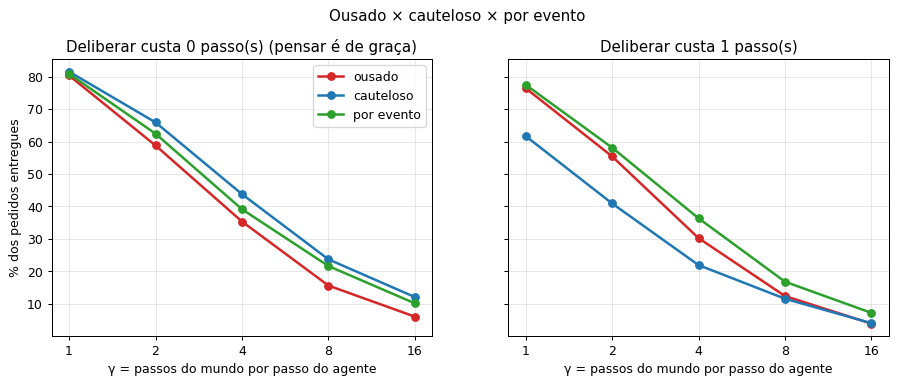

                   γ=1     γ=2     γ=4     γ=8    γ=16
custo = 0
  ousado           80%     59%     35%     16%      6%
  cauteloso        82%     66%     44%     24%     12%
  por evento       81%     62%     39%     22%     10%
custo = 1
  ousado           76%     55%     30%     12%      4%
  cauteloso        62%     41%     22%     12%      4%
  por evento       78%     58%     36%     17%      7%


In [6]:
# 🧪 Experimento de Kinny e Georgeff (1991): qual compromisso é melhor quando o mundo muda rápido?
def eficacia(estrategia, gama, custo, rodadas=12, passos=600):
    total_entregues = total_surgidos = 0
    for s in range(rodadas):
        cidade, ag = Cidade(gama, semente=100 + s), EntregadorBDI(estrategia, custo)
        for _ in range(passos):
            ag.passo(cidade)
        total_entregues += ag.entregues
        total_surgidos += cidade.surgidos
    return 100 * total_entregues / total_surgidos

GAMAS = [1, 2, 4, 8, 16]
ESTRATEGIAS = {'ousado': CORES['vermelho'], 'cauteloso': CORES['azul'], 'por evento': CORES['verde']}
resultados = {(e, g, c): eficacia(e, g, c) for e in ESTRATEGIAS for g in GAMAS for c in (0, 1)}

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, custo in zip(axs, (0, 1)):
    for e, cor in ESTRATEGIAS.items():
        ax.plot(GAMAS, [resultados[(e, g, custo)] for g in GAMAS], 'o-', color=cor, lw=2, label=e)
    ax.set_xscale('log', base=2); ax.set_xticks(GAMAS); ax.set_xticklabels(GAMAS)
    ax.set_xlabel('γ = passos do mundo por passo do agente')
    ax.set_title(f'Deliberar custa {custo} passo(s)' + (' (pensar é de graça)' if custo == 0 else ''))
    ax.grid(alpha=0.3)
axs[0].set_ylabel('% dos pedidos entregues'); axs[0].legend()
plt.suptitle('Ousado × cauteloso × por evento', y=1.02); plt.show()

print(f'{"":>14}' + ''.join(f'{"γ=" + str(g):>8}' for g in GAMAS))
for custo in (0, 1):
    print(f'custo = {custo}')
    for e in ESTRATEGIAS:
        print(f'  {e:<12}' + ''.join(f'{resultados[(e, g, custo)]:>7.0f}%' for g in GAMAS))


#### 🔎 Como interpretar os gráficos

**Esquerda: pensar é de graça (custo 0).**
- Com o mundo **quase parado** (γ = 1), as três estratégias empatam (~80%): se nada muda, reconsiderar não traz informação nova.
- Com o mundo **mudando rápido**, o **cauteloso vence** (44% × 35% do ousado com γ = 4; 12% × 6% com γ = 16). O ousado faz viagens inúteis até pedidos já cancelados e não percebe pedidos novos mais próximos.

**Direita: deliberar custa 1 passo.**
- O **cauteloso despenca** (62% com γ = 1, contra 76% do ousado): ele passa metade do tempo parado "olhando o app".
- O **por evento vence em todas as velocidades** (78%, 58%, 36%, 17%, 7%): reconsidera **só quando é útil** e paga o custo poucas vezes.
- Esse é exatamente o resultado qualitativo de Kinny e Georgeff: **agentes ousados vão melhor em mundos estáveis, cautelosos em mundos dinâmicos**, e o custo de deliberar decide o empate.

**Por que isso importa fora da sala de aula?**
- **Engenharia de software:** "reconsiderar a cada passo" é o *polling* (perguntar ao servidor a cada segundo se algo mudou); "por evento" são as **notificações push**, os *webhooks* e as interrupções. Sistemas reais preferem eventos pelo mesmo motivo do gráfico.
- **Agentes com LLM** (Seção 8): cada "reconsideração" é uma chamada ao modelo, que custa **dinheiro e segundos**. Decidir **quando** o agente deve replanejar é uma das principais escolhas de projeto.
- **Gestão:** empresas que revisam o planejamento todo dia não executam nada; empresas que nunca revisam insistem em projetos mortos. Revisar quando chega um **sinal relevante** é o meio-termo.

## 3. Comunicação entre Agentes

### 3.0 Falar é agir: a teoria dos atos de fala

A comunicação entre agentes se apoia em uma ideia da filosofia da linguagem. **J. L. Austin** (1962) observou que muitas frases não descrevem o mundo, **mudam** o mundo: "prometo entregar até as 20h", "aceito a proposta", "declaro aberta a sessão". Quem diz isso está **realizando uma ação**. **John Searle** (1969) organizou esses **atos de fala** em categorias (assertivos, diretivos, compromissivos, expressivos, declarativos).

Para agentes, isso significa que **cada mensagem tem duas partes**:
- a **performativa** (a intenção do ato: informar, pedir, propor, recusar...);
- o **conteúdo** (sobre o quê).

"Entregar o pedido P-4821" pode ser um **pedido** (REQUEST), uma **promessa** (AGREE) ou um **relato** (INFORM, "já entreguei"). O conteúdo é o mesmo, mas o efeito é completamente diferente. A primeira linguagem de agentes a explorar isso foi a **KQML** (Finin et al., 1994); depois veio a **FIPA ACL**.

### 3.1 FIPA ACL (Agent Communication Language)

Linguagem padrão para comunicação entre agentes (FIPA, 2002), baseada em **atos de fala**. A especificação define 22 atos comunicativos.

**Performativas principais:**
- **INFORM:** Informar um fato
- **REQUEST:** Solicitar ação
- **QUERY:** Fazer pergunta
- **CFP (Call for Proposals):** Pedir propostas (abre uma licitação)
- **PROPOSE:** Propor algo
- **ACCEPT-PROPOSAL:** Aceitar proposta
- **REJECT-PROPOSAL:** Rejeitar proposta
- **AGREE:** Concordar em fazer algo
- **REFUSE:** Recusar fazer algo

**Estrutura de mensagem:**
```
(performativa
  :sender agente1
  :receiver agente2
  :content "conteúdo da mensagem"
  :language "linguagem do conteúdo"
  :ontology "ontologia usada"
)
```

**Por que a `:ontology`?** Os dois agentes precisam concordar sobre **o que as palavras significam**. Para **Gruber** (1993), uma ontologia é uma *especificação explícita de uma conceitualização*. Exemplo brasileiro bem prático: a **Nota Fiscal eletrônica (NF-e)** só funciona porque milhares de sistemas diferentes, de empresas diferentes, seguem o **mesmo esquema** do que é "emitente", "produto", "CFOP" e "valor do ICMS". Sem esse vocabulário comum, cada sistema entenderia a nota de um jeito.

### 3.2 Protocolos de Interação

**Contract Net Protocol:** Alocação de tarefas via licitação (Seção 4).

**Leilões:** Vários tipos (inglês, holandês, selado) (Seção 5).

**Negociação:** Agentes negociam termos mutuamente aceitáveis, trocando propostas e contrapropostas (Rosenschein e Zlotkin, 1994).

Um **protocolo** define quais mensagens podem vir depois de quais: depois de um CFP, só faz sentido responder com PROPOSE ou REFUSE; depois de um PROPOSE, com ACCEPT-PROPOSAL ou REJECT-PROPOSAL. Isso permite que agentes de **empresas diferentes**, escritos por **equipes diferentes**, conversem sem combinar nada antes.

### 3.3 🧪 A mesma conversa em FIPA ACL e em JSON

Vamos escrever a conversa entre uma plataforma de entregas e um entregador nos dois formatos: o padrão FIPA ACL e o JSON, formato usado hoje por praticamente todas as APIs web.

In [7]:
# ✉️ A mesma conversa em FIPA ACL (padrão de 2002) e em JSON (o formato das APIs e protocolos atuais, como o A2A)
def para_fipa_acl(m):
    campos = '\n'.join(f'  :{k} {json.dumps(v, ensure_ascii=False) if isinstance(v, dict) else v}'
                       for k, v in m.items() if k != 'performativa')
    return f'({m["performativa"]}\n{campos}\n)'

conversa = [
    {'performativa': 'cfp', 'sender': 'plataforma', 'receiver': 'entregador_17',
     'content': {'pedido': 'P-4821', 'retirada': 'Pizzaria, R. Augusta 900', 'entrega': 'Av. Paulista 1578', 'prazo_min': 35},
     'language': 'json', 'ontology': 'entregas-v1', 'protocol': 'fipa-contract-net',
     'conversation-id': 'conv-P-4821', 'reply-by': '19:42:00'},
    {'performativa': 'propose', 'sender': 'entregador_17', 'receiver': 'plataforma',
     'content': {'pedido': 'P-4821', 'chega_em_min': 12, 'valor': 9.50},
     'conversation-id': 'conv-P-4821', 'in-reply-to': 'cfp'},
    {'performativa': 'accept-proposal', 'sender': 'plataforma', 'receiver': 'entregador_17',
     'content': {'pedido': 'P-4821'}, 'conversation-id': 'conv-P-4821'},
    {'performativa': 'inform', 'sender': 'entregador_17', 'receiver': 'plataforma',
     'content': {'pedido': 'P-4821', 'status': 'entregue', 'hora': '20:09'}, 'conversation-id': 'conv-P-4821'},
]

print('1) A primeira mensagem em FIPA ACL:\n')
print(para_fipa_acl(conversa[0]))
print('\n2) A mesma mensagem em JSON:\n')
print(json.dumps(conversa[0], ensure_ascii=False, indent=2))
print('\n3) A conversa inteira (protocolo Contract Net):\n')
for m in conversa:
    print(f'  {m["sender"]:>14} ──{m["performativa"]:^17}──▶ {m["receiver"]:<14} {m["content"]}')


1) A primeira mensagem em FIPA ACL:

(cfp
  :sender plataforma
  :receiver entregador_17
  :content {"pedido": "P-4821", "retirada": "Pizzaria, R. Augusta 900", "entrega": "Av. Paulista 1578", "prazo_min": 35}
  :language json
  :ontology entregas-v1
  :protocol fipa-contract-net
  :conversation-id conv-P-4821
  :reply-by 19:42:00
)

2) A mesma mensagem em JSON:

{
  "performativa": "cfp",
  "sender": "plataforma",
  "receiver": "entregador_17",
  "content": {
    "pedido": "P-4821",
    "retirada": "Pizzaria, R. Augusta 900",
    "entrega": "Av. Paulista 1578",
    "prazo_min": 35
  },
  "language": "json",
  "ontology": "entregas-v1",
  "protocol": "fipa-contract-net",
  "conversation-id": "conv-P-4821",
  "reply-by": "19:42:00"
}

3) A conversa inteira (protocolo Contract Net):

      plataforma ──       cfp       ──▶ entregador_17  {'pedido': 'P-4821', 'retirada': 'Pizzaria, R. Augusta 900', 'entrega': 'Av. Paulista 1578', 'prazo_min': 35}
   entregador_17 ──     propose     ──▶ pl

#### 🔎 Como interpretar o resultado

- **O conteúdo é idêntico nos dois formatos.** Muda só a "embalagem": FIPA ACL usa a sintaxe de listas do Lisp (comum na IA dos anos 1990); JSON é o formato das APIs web atuais. **Os conceitos sobreviveram**, a sintaxe mudou.
- **Campos que fazem diferença na prática:**
  - `conversation-id` liga todas as mensagens do mesmo pedido. Com centenas de conversas simultâneas, é assim que o agente sabe a qual negociação cada resposta pertence;
  - `reply-by` é o prazo para responder: quem não responder até 19:42 está fora da licitação. Sem isso, a plataforma esperaria para sempre por um entregador desconectado;
  - `protocol` diz qual "roteiro" a conversa segue, e `ontology` diz qual vocabulário o `content` usa.
- **A conversa inteira segue o Contract Net:** `cfp` → `propose` → `accept-proposal` → `inform`. Cada performativa é um **ato**: o `propose` é um compromisso condicional ("se você aceitar, eu faço por R$ 9,50"); o `accept-proposal` fecha o contrato.

### 3.4 Do Actor Model ao WhatsApp e aos protocolos dos agentes de IA

As ideias desta seção estão em sistemas que você usa todos os dias:

| Ideia clássica | Onde está hoje |
|---|---|
| **Actor Model** (Hewitt, Bishop e Steiger, 1973): entidades independentes que só se comunicam por **mensagens assíncronas**, cada uma com sua caixa de entrada | A linguagem **Erlang** (Ericsson, anos 1980; Armstrong, 2003) segue esse modelo e é a base do *backend* do **WhatsApp**. Também estão nele o **Akka** (JVM) e o **Microsoft Orleans**, usado em serviços de jogos on-line como *Halo 4* (Bernstein et al., 2014) |
| **Caixa de mensagens** de cada agente | Filas e *brokers* de mensagens como **Kafka** e **RabbitMQ**, presentes em praticamente todo sistema de *e-commerce* e banco digital |
| **Directory Facilitator** da FIPA (as "páginas amarelas" onde agentes anunciam o que sabem fazer) | O **Agent Card** do protocolo **A2A** (Google, 2025): um arquivo JSON em que cada agente de IA descreve suas habilidades para que outros o encontrem |
| **Atuadores** de um agente | O **MCP** (*Model Context Protocol*, Anthropic, 2024) padroniza como um agente com LLM acessa **ferramentas**: bancos de dados, APIs, arquivos |
| **ACL e protocolos de interação** | O **A2A** define como agentes de IA de empresas diferentes trocam **tarefas** e **mensagens** entre si |

> 💡 **Moral da história:** quando ouvir falar do "novo protocolo para agentes de IA", pergunte-se qual problema da FIPA ele está resolvendo de novo. Quase sempre é o mesmo: **descobrir** quem sabe fazer o quê, **pedir** algo com uma intenção clara e **acompanhar** a conversa até o fim.

## 4. Implementação de Sistema Multiagente Simples

In [25]:
from typing import List, Dict, Any
from dataclasses import dataclass, field
from enum import Enum
import random

class Performativa(Enum):
    """Tipos de atos de fala."""
    INFORM = "inform"
    REQUEST = "request"
    PROPOSE = "propose"
    ACCEPT = "accept"
    REJECT = "reject"

@dataclass
class Mensagem:
    """Mensagem entre agentes."""
    performativa: Performativa
    remetente: str
    destinatario: str
    conteudo: Any
    
    def __repr__(self):
        return f"{self.remetente} -> {self.destinatario}: {self.performativa.value}({self.conteudo})"

class Agente:
    """
    Classe base para agente autônomo.
    """
    
    def __init__(self, nome: str, sistema=None):
        self.nome = nome
        self.sistema = sistema  # Referência ao sistema multiagente
        self.caixa_mensagens: List[Mensagem] = []
        self.conhecimento: Dict[str, Any] = {}
    
    def set_sistema(self, sistema):
        """Define referência ao sistema após criação."""
        self.sistema = sistema
        
    def receber_mensagem(self, mensagem: Mensagem):
        """Recebe mensagem de outro agente."""
        self.caixa_mensagens.append(mensagem)
    
    def enviar_mensagem(self, destinatario: 'Agente', performativa: Performativa, conteudo: Any):
        """Envia mensagem para outro agente."""
        mensagem = Mensagem(performativa, self.nome, destinatario.nome, conteudo)
        destinatario.receber_mensagem(mensagem)
        return mensagem
    
    def processar_mensagens(self):
        """Processa mensagens recebidas."""
        while self.caixa_mensagens:
            mensagem = self.caixa_mensagens.pop(0)
            self.processar_mensagem(mensagem)
    
    def processar_mensagem(self, mensagem: Mensagem):
        """Processa uma mensagem específica. Override em subclasses."""
        pass
    
    def agir(self):
        """Executa ação do agente. Override em subclasses."""
        pass

class AgenteContratante(Agente):
    """
    Agente que solicita tarefas (Contract Net Protocol).
    """
    
    def __init__(self, nome: str, sistema=None):
        super().__init__(nome, sistema)
        self.tarefas = []
        self.propostas_recebidas = []
    
    def anunciar_tarefa(self, tarefa: Dict, fornecedores: List['AgenteFornecedor']):
        """Anuncia tarefa para fornecedores potenciais."""
        print(f"\n{self.nome}: Anunciando tarefa '{tarefa['descricao']}'")
        self.tarefas.append(tarefa)
        self.propostas_recebidas = []
        
        for fornecedor in fornecedores:
            self.enviar_mensagem(fornecedor, Performativa.REQUEST, tarefa)
    
    def processar_mensagem(self, mensagem: Mensagem):
        """Processa propostas de fornecedores."""
        if mensagem.performativa == Performativa.PROPOSE:
            proposta = mensagem.conteudo
            print(f"  {self.nome} recebeu proposta de {mensagem.remetente}: R${proposta['preco']}")
            self.propostas_recebidas.append({
                'fornecedor': mensagem.remetente,
                'proposta': proposta
            })
    
    def selecionar_vencedor(self, sistema):
        """Seleciona melhor proposta."""
        if not self.propostas_recebidas:
            print(f"  {self.nome}: Nenhuma proposta recebida")
            return
        
        # Seleciona menor preço
        melhor = min(self.propostas_recebidas, key=lambda x: x['proposta']['preco'])
        
        print(f"\n  {self.nome}: Selecionou {melhor['fornecedor']} (R${melhor['proposta']['preco']})")
        
        # Notifica vencedor e perdedores
        for prop in self.propostas_recebidas:
            fornecedor = sistema.obter_agente(prop['fornecedor'])
            if prop == melhor:
                self.enviar_mensagem(fornecedor, Performativa.ACCEPT, prop['proposta'])
            else:
                self.enviar_mensagem(fornecedor, Performativa.REJECT, prop['proposta'])

class AgenteFornecedor(Agente):
    """
    Agente que fornece serviços/produtos.
    """
    
    def __init__(self, nome: str, capacidade: int, custo_base: float, sistema=None):
        super().__init__(nome, sistema)
        self.capacidade = capacidade
        self.custo_base = custo_base
        self.tarefas_em_execucao = 0
    
    def processar_mensagem(self, mensagem: Mensagem):
        """Responde a solicitações e aceites."""
        if mensagem.performativa == Performativa.REQUEST:
            tarefa = mensagem.conteudo
            
            # Verifica capacidade
            if self.tarefas_em_execucao < self.capacidade:
                # Calcula preço com variação
                preco = self.custo_base * tarefa.get('complexidade', 1.0)
                preco *= random.uniform(0.9, 1.1)  # Variação
                
                proposta = {
                    'tarefa_id': tarefa['id'],
                    'preco': round(preco, 2),
                    'prazo': random.randint(1, 5)
                }
                
                # Envia proposta diretamente ao contratante
                if self.sistema:
                    contratante = self.sistema.obter_agente(mensagem.remetente)
                    if contratante:
                        self.enviar_mensagem(contratante, Performativa.PROPOSE, proposta)
        
        elif mensagem.performativa == Performativa.ACCEPT:
            print(f"    ✓ {self.nome}: Proposta ACEITA!")
            self.tarefas_em_execucao += 1
        
        elif mensagem.performativa == Performativa.REJECT:
            print(f"    ✗ {self.nome}: Proposta rejeitada")

class SistemaMultiagente:
    """
    Ambiente que gerencia múltiplos agentes.
    """
    
    def __init__(self):
        self.agentes: Dict[str, Agente] = {}
    
    def adicionar_agente(self, agente: Agente):
        """Registra agente no sistema."""
        self.agentes[agente.nome] = agente
        agente.set_sistema(self)  # Define referência ao sistema
        print(f"Agente '{agente.nome}' registrado no sistema")
    
    def obter_agente(self, nome: str) -> Agente:
        """Busca agente por nome."""
        return self.agentes.get(nome)
    
    def executar_ciclo(self):
        """Executa um ciclo de processamento."""
        for agente in self.agentes.values():
            agente.processar_mensagens()
            agente.agir()

# Exemplo de uso: Mercado de tarefas
print("="*60)
print("SISTEMA MULTIAGENTE - CONTRACT NET PROTOCOL")
print("="*60)

# Cria sistema
sistema = SistemaMultiagente()

# Cria agentes
print("\nCriando agentes...\n")
contratante = AgenteContratante("Empresa_X")
sistema.adicionar_agente(contratante)

fornecedores = [
    AgenteFornecedor("Fornecedor_A", capacidade=3, custo_base=1000),
    AgenteFornecedor("Fornecedor_B", capacidade=2, custo_base=900),
    AgenteFornecedor("Fornecedor_C", capacidade=5, custo_base=1100),
]

for f in fornecedores:
    sistema.adicionar_agente(f)

# Simula licitação
print("\n" + "="*60)
print("LICITAÇÃO DE TAREFA")
print("="*60)

tarefa = {
    'id': 'T001',
    'descricao': 'Desenvolvimento de sistema web',
    'complexidade': 1.5
}

# Fase 1: Anúncio
contratante.anunciar_tarefa(tarefa, fornecedores)

# Fase 2: Fornecedores processam e enviam propostas automaticamente
for f in fornecedores:
    f.processar_mensagens()

# Fase 3: Contratante processa propostas
contratante.processar_mensagens()

# Fase 4: Contratante seleciona vencedor
contratante.selecionar_vencedor(sistema)

# Fase 5: Fornecedores processam resposta
print("\nProcessando respostas...")
for f in fornecedores:
    f.processar_mensagens()

print("\n" + "="*60)

SISTEMA MULTIAGENTE - CONTRACT NET PROTOCOL

Criando agentes...

Agente 'Empresa_X' registrado no sistema
Agente 'Fornecedor_A' registrado no sistema
Agente 'Fornecedor_B' registrado no sistema
Agente 'Fornecedor_C' registrado no sistema

LICITAÇÃO DE TAREFA

Empresa_X: Anunciando tarefa 'Desenvolvimento de sistema web'
  Empresa_X recebeu proposta de Fornecedor_A: R$1509.01
  Empresa_X recebeu proposta de Fornecedor_B: R$1223.59
  Empresa_X recebeu proposta de Fornecedor_C: R$1561.8

  Empresa_X: Selecionou Fornecedor_B (R$1223.59)

Processando respostas...
    ✗ Fornecedor_A: Proposta rejeitada
    ✓ Fornecedor_B: Proposta ACEITA!
    ✗ Fornecedor_C: Proposta rejeitada



**Observações:**

1. **Contract Net Protocol:** Padrão clássico onde um agente contratante anuncia tarefa, agentes fornecedores enviam propostas, e contratante seleciona melhor proposta.

2. **Autonomia:** Cada fornecedor decide autonomamente se envia proposta (baseado em capacidade) e qual preço cobrar.

3. **Comunicação assíncrona:** Mensagens são armazenadas em caixas de mensagens e processadas quando agente está pronto.

4. **Escalabilidade:** Sistema pode facilmente acomodar novos fornecedores sem modificar lógica existente.

#### 🔎 Como interpretar o resultado

- **Fase 1 (anúncio):** a `Empresa_X` envia um `REQUEST` com a tarefa para os três fornecedores. Ela **não sabe** quem é o melhor; descobre isso pelas respostas. Esse é o ponto central do protocolo: **a informação está distribuída** (só cada fornecedor sabe o próprio custo e a própria capacidade).
- **Fase 2 (propostas):** cada fornecedor calcula **sozinho** seu preço: `custo_base × complexidade`, com variação aleatória de ±10%. Como a variação é aleatória, os preços e o vencedor podem mudar a cada execução. O `Fornecedor_B` (custo base 900) costuma vencer, mas não sempre.
- **Fases 3 a 5 (adjudicação):** o contratante escolhe o menor preço e envia `ACCEPT` ao vencedor e `REJECT` aos demais. Só o vencedor aumenta `tarefas_em_execucao`.
- **O que falta para um sistema real:** prazo para responder (quem não responde trava o contratante), critério com mais de um atributo (preço **e** prazo **e** reputação) e a possibilidade de o fornecedor **recusar** (`REFUSE`) quando estiver sem capacidade. Os exercícios no final pedem algumas dessas extensões.

### 4.1 As quatro fases do Contract Net

O protocolo de **Smith** (1980), refinado por **Smith e Davis** (1981), imita uma **licitação**:

| Fase | Mensagem | Quem envia | No app de entregas |
|---|---|---|---|
| 1. Anúncio | `CFP` (*call for proposals*) | Gerente (contratante) | "Novo pedido na Pizzaria X, quem pega?" |
| 2. Propostas | `PROPOSE` ou `REFUSE` | Candidatos | "Chego em 12 min" / "Estou ocupado" |
| 3. Adjudicação | `ACCEPT-PROPOSAL` / `REJECT-PROPOSAL` | Gerente | O pedido aparece para um entregador só |
| 4. Execução | `INFORM` (resultado) ou `FAILURE` | Vencedor | "Pedido entregue às 20:09" |

### 4.2 🛵 Contract Net num app de entregas: o que o entregador deve "ofertar"?

Uma plataforma de entregas recebe **8 pedidos**, um de cada vez, e tem **4 entregadores**, cada um podendo levar **até 2 pedidos** na mesma rota (o famoso "agrupamento" de pedidos). A plataforma anuncia cada pedido e escolhe o menor lance. Mas **o que** cada entregador deve informar como lance?

- **Lance ingênuo:** "estou a X km deste pedido", medindo da posição **atual**, como se ele não tivesse aceitado nada antes;
- **Lance por custo marginal** (**Sandholm**, 1993): "se eu aceitar este pedido, minha rota **aumenta** X km", levando em conta os pedidos que ele **já aceitou**.

Sandholm propôs o custo marginal no sistema **TRACONET**, em que centros de distribuição de transporte negociavam entregas entre si. Vamos comparar com uma alocação **aleatória** e com o **ótimo centralizado**, calculado por força bruta sobre todas as 65.536 formas de distribuir os pedidos.

Estratégia                       km totais   acima do ótimo   mensagens
Aleatório (média de 200)              40.3              72%           —
Contract Net, lance ingênuo           42.3              81%          96
Contract Net, custo marginal          30.8              32%          96
Ótimo centralizado                    23.4               0%           —


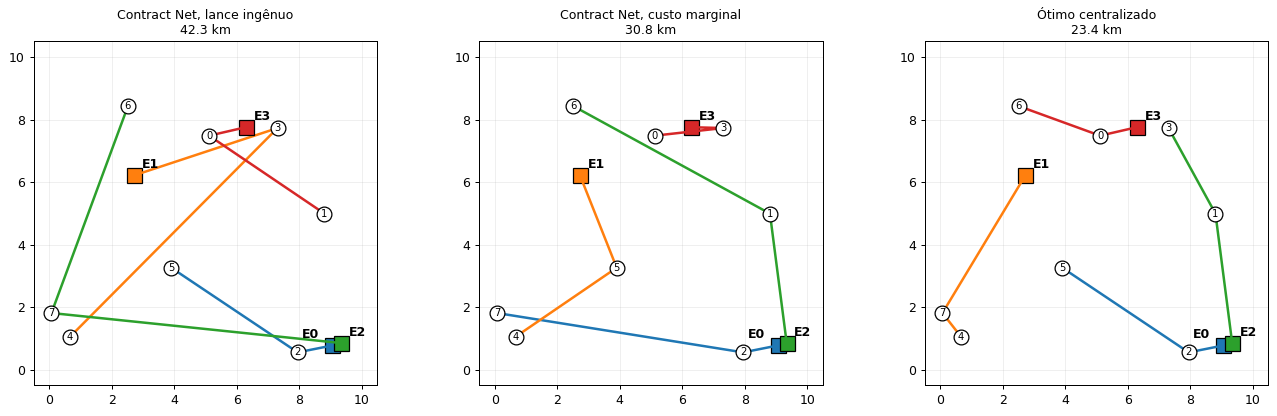

In [26]:
# 🛵 Contract Net aplicado a um app de entregas: lance ingênuo × lance por CUSTO MARGINAL (Sandholm, 1993)
rng = np.random.default_rng(46)
N_ENT, N_PED, CAPACIDADE = 4, 8, 2
pos_ent = rng.uniform(0, 10, (N_ENT, 2))          # onde está cada entregador (km)
pos_ped = rng.uniform(0, 10, (N_PED, 2))          # onde está cada pedido (simplificação: um ponto por pedido)

def km_percurso(e, ordem):
    pontos = [pos_ent[e]] + [pos_ped[p] for p in ordem]
    return sum(np.linalg.norm(a - b) for a, b in zip(pontos, pontos[1:]))

def melhor_ordem(e, pedidos):
    # melhor ordem de visita (força bruta: com no máximo 2 pedidos, são só 2 ordens possíveis)
    return min(itertools.permutations(pedidos), key=lambda o: km_percurso(e, o))

def custo_rota(e, pedidos):
    return km_percurso(e, melhor_ordem(e, pedidos)) if pedidos else 0.0

def total_km(alocacao):
    return sum(custo_rota(e, alocacao[e]) for e in range(N_ENT))

def contract_net(tipo_lance):
    alocacao = {e: [] for e in range(N_ENT)}
    for p in range(N_PED):                                   # pedidos chegam um a um e são anunciados (CFP)
        lances = {}
        for e in range(N_ENT):
            if len(alocacao[e]) >= CAPACIDADE:
                continue                                     # entregador cheio recusa (REFUSE)
            if tipo_lance == 'ingênuo':                      # "estou a X km do pedido", ignora o que já aceitou
                lances[e] = np.linalg.norm(pos_ent[e] - pos_ped[p])
            else:                                            # "aceitar este pedido aumenta minha rota em X km"
                lances[e] = custo_rota(e, alocacao[e] + [p]) - custo_rota(e, alocacao[e])
        vencedor = min(lances, key=lances.get)               # ACCEPT para o menor lance, REJECT para os demais
        alocacao[vencedor].append(p)
    return alocacao

def otimo_centralizado():
    melhor, melhor_aloc = np.inf, None
    for atribuicao in itertools.product(range(N_ENT), repeat=N_PED):      # 4^8 = 65.536 possibilidades
        if max(Counter(atribuicao).values()) > CAPACIDADE:
            continue
        aloc = {e: [p for p in range(N_PED) if atribuicao[p] == e] for e in range(N_ENT)}
        km = total_km(aloc)
        if km < melhor:
            melhor, melhor_aloc = km, aloc
    return melhor_aloc

def aleatorio(semente):
    r = random.Random(semente)
    vagas = [e for e in range(N_ENT) for _ in range(CAPACIDADE)]
    r.shuffle(vagas)
    return {e: [p for p in range(N_PED) if vagas[p] == e] for e in range(N_ENT)}

estrategias = {
    'Aleatório (média de 200)': None,
    'Contract Net, lance ingênuo': contract_net('ingênuo'),
    'Contract Net, custo marginal': contract_net('marginal'),
    'Ótimo centralizado': otimo_centralizado(),
}
km_aleatorio = np.mean([total_km(aleatorio(s)) for s in range(200)])
km_otimo = total_km(estrategias['Ótimo centralizado'])
print(f'{"Estratégia":<32}{"km totais":>10}{"acima do ótimo":>17}{"mensagens":>12}')
for nome, aloc in estrategias.items():
    km = km_aleatorio if aloc is None else total_km(aloc)
    msgs = '—' if 'Contract' not in nome else str(N_PED * 3 * N_ENT)   # por pedido: CFP + resposta + aceite/rejeição
    print(f'{nome:<32}{km:>10.1f}{100 * (km / km_otimo - 1):>16.0f}%{msgs:>12}')

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, nome in zip(axs, list(estrategias)[1:]):
    aloc = estrategias[nome]
    for e in range(N_ENT):
        cor = plt.cm.tab10(e)
        ax.plot(*pos_ent[e], 's', ms=12, color=cor, mec='black')
        ax.annotate(f'E{e}', pos_ent[e], xytext=(6, 6) if e != 0 else (-24, 6), textcoords='offset points', fontweight='bold')
        if aloc[e]:
            rota = np.array([pos_ent[e]] + [pos_ped[p] for p in melhor_ordem(e, aloc[e])])
            ax.plot(rota[:, 0], rota[:, 1], '-', color=cor, lw=2)
    ax.scatter(pos_ped[:, 0], pos_ped[:, 1], s=140, color='white', edgecolor='black', zorder=3)
    for p in range(N_PED):
        ax.annotate(f'{p}', pos_ped[p], ha='center', va='center', fontsize=8, zorder=4)
    ax.set_title(f'{nome}\n{total_km(aloc):.1f} km', fontsize=10)
    ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.5, 10.5); ax.set_aspect('equal'); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()


#### 🔎 Como interpretar o resultado

- **O lance ingênuo foi PIOR que o aleatório** (42,3 km contra 40,3 km, 81% acima do ótimo). Olhe o mapa da esquerda: o entregador **E1** (laranja) aceitou o pedido 3 e depois "ofereceu" o pedido 4 medindo a distância a partir da **posição inicial**, como se estivesse livre. Resultado: uma rota em ziguezague que cruza o mapa. **Um protocolo bom com lances ruins produz uma alocação ruim.**
- **O lance por custo marginal economizou 27% dos km** (30,8 km) com **exatamente o mesmo protocolo** e o mesmo número de mensagens. Só mudou a **informação** que cada agente coloca no lance. Ainda assim, ficou 32% acima do ótimo.
- **Por que o Contract Net não chega ao ótimo?** Porque é **guloso e sequencial**: o pedido 0 é entregue a quem estiver melhor **naquele momento**, sem saber quais pedidos virão depois, e a decisão não é desfeita. Sandholm (1998) estudou contratos que permitem **renegociar** e trocar tarefas depois, aproximando-se do ótimo.
- **Então por que não usar sempre o ótimo centralizado?**
  1. **Explosão combinatória:** foram 65.536 combinações para 8 pedidos e 4 entregadores; com 100 pedidos e 50 entregadores, seriam 50¹⁰⁰, um número impossível de percorrer (o mesmo problema das buscas cegas da Aula 03);
  2. **Informação privada:** só o entregador sabe se a moto está com pouca gasolina, se ele conhece um atalho ou se vai parar para almoçar;
  3. **Tempo:** o cliente não espera a plataforma "pensar" por minutos.
- **Na prática**, plataformas de entrega e de transporte combinam as duas ideias: juntam os pedidos de uma **janela de poucos segundos** e resolvem um problema de **emparelhamento** (como o algoritmo húngaro, Kuhn, 1955) com heurísticas, deixando ao entregador a decisão final de aceitar ou recusar a oferta.
- **Mensagens:** 96 mensagens (8 pedidos × 4 entregadores × 3 mensagens: CFP, resposta e aceite/rejeição). Em uma cidade com milhares de entregadores, anunciar para **todos** seria inviável; por isso o anúncio vai só para quem está **perto**, uma otimização sugerida já por Smith (1980).

## 5. Leilões: mecanismos de mercado entre agentes

Leilões são a forma mais usada de **alocar recursos entre agentes com interesses próprios** quando ninguém sabe quanto o recurso vale para os outros. A teoria por trás deles, o **desenho de mecanismos**, rendeu três prêmios Nobel de Economia: **William Vickrey** (1996), **Leonid Hurwicz, Eric Maskin e Roger Myerson** (2007) e **Paul Milgrom e Robert Wilson** (2020).

| Formato | Como funciona | Onde aparece |
|---|---|---|
| **Inglês** (ascendente, aberto) | O preço sobe até restar um interessado | Leilões de arte, de veículos apreendidos, de imóveis |
| **Holandês** (descendente, aberto) | O preço cai até alguém aceitar | Leilão de **flores** na Holanda (Royal FloraHolland, Aalsmeer), em que um relógio baixa o preço em segundos |
| **1º preço selado** | Lances secretos; o maior vence e paga **o próprio lance** | Licitações em envelope fechado |
| **2º preço selado (Vickrey)** | Lances secretos; o maior vence e paga **o 2º maior lance** | Base teórica dos lances automáticos do eBay e dos leilões de anúncios |
| **Reverso** | Vários vendedores disputam **um comprador**; vence o **menor** preço | **Pregão eletrônico** nas compras públicas brasileiras (Lei 10.520/2002 e Lei 14.133/2021) |
| **Leilão de posições** (GSP) | Várias posições de anúncio, cada vencedor paga o lance do próximo | **Google Ads** (Edelman, Ostrovsky e Schwarz, 2007; Varian, 2007) |
| **VCG** | Generaliza o Vickrey para vários itens | Anúncios do Facebook (Varian e Harris, 2014) |
| **Leilões de espectro** | Vários lotes de frequências vendidos de uma vez | O leilão do **5G** realizado pela Anatel em novembro de 2021 |

**Por que isso é assunto de SMA?** Nos anúncios on-line, um leilão acontece **a cada busca ou página carregada**, em milissegundos. Nenhum humano dá esses lances: quem os dá são **agentes de software** dos anunciantes, competindo entre si bilhões de vezes por dia.

### 5.1 🧪 Quanto ofertar? Leilão de 1º preço × leilão de 2º preço (Vickrey)

Você quer um item que vale **R$ 70 para você**. Há outros 4 licitantes, cada um com um valor sorteado entre R$ 0 e R$ 100 que você não conhece. Qual lance maximiza o seu **lucro** (valor − preço pago, ou zero se perder)? Simulamos 50 mil leilões para cada lance possível.

1º preço: melhor lance = R$  56 → lucro médio R$  3.36 | lance = valor (R$ 70) → R$  0.00 | exagerar (R$ 90) → R$ -20.00
2º preço: melhor lance = R$  70 → lucro médio R$  3.32 | lance = valor (R$ 70) → R$  3.32 | exagerar (R$ 90) → R$ -1.32


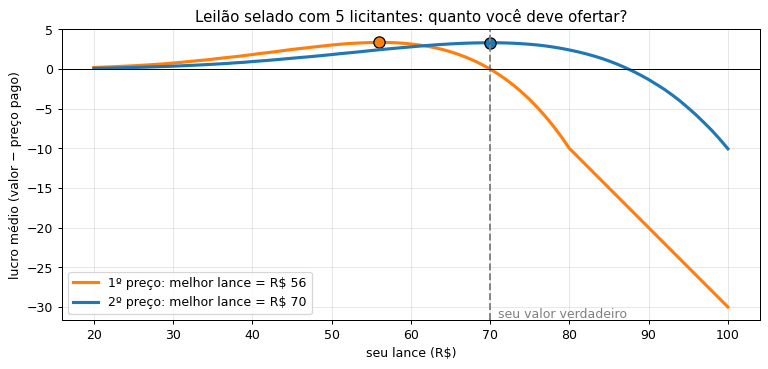

In [27]:
# 🔨 Por que, no leilão de 2º preço (Vickrey, 1961), dar o seu valor VERDADEIRO é a melhor estratégia?
rng = np.random.default_rng(42)
N_LICITANTES, N_SIM, MEU_VALOR = 5, 50_000, 70           # quanto o item realmente vale PARA VOCÊ: R$ 70
valores_rivais = rng.uniform(0, 100, (N_SIM, N_LICITANTES - 1))

def utilidade_esperada(meu_lance, regra):
    if regra == '1º preço':        # rivais jogam o equilíbrio do 1º preço: lance = (n-1)/n × valor
        maior_rival = valores_rivais.max(axis=1) * (N_LICITANTES - 1) / N_LICITANTES
        preco = meu_lance
    else:                          # rivais dão o valor verdadeiro; o vencedor paga o 2º maior lance
        maior_rival = valores_rivais.max(axis=1)
        preco = maior_rival
    ganhou = meu_lance > maior_rival
    return np.mean(np.where(ganhou, MEU_VALOR - preco, 0.0))

lances = np.arange(20, 101, 1)
fig, ax = plt.subplots(figsize=(10, 4.2))
for regra, cor in [('1º preço', CORES['laranja']), ('2º preço', CORES['azul'])]:
    u = np.array([utilidade_esperada(b, regra) for b in lances])
    melhor = lances[u.argmax()]
    ax.plot(lances, u, color=cor, lw=2.5, label=f'{regra}: melhor lance = R$ {melhor}')
    ax.plot(melhor, u.max(), 'o', ms=9, color=cor, mec='black')
    print(f'{regra}: melhor lance = R$ {melhor:3d} → lucro médio R$ {u.max():5.2f} | '
          f'lance = valor (R$ 70) → R$ {utilidade_esperada(70, regra):5.2f} | '
          f'exagerar (R$ 90) → R$ {utilidade_esperada(90, regra):5.2f}')
ax.axvline(MEU_VALOR, ls='--', color='gray'); ax.text(MEU_VALOR + 1, ax.get_ylim()[0] + 0.3, 'seu valor verdadeiro', color='gray')
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('seu lance (R$)'); ax.set_ylabel('lucro médio (valor − preço pago)')
ax.set_title(f'Leilão selado com {N_LICITANTES} licitantes: quanto você deve ofertar?')
ax.legend(); ax.grid(alpha=0.3); plt.show()


#### 🔎 Como interpretar o resultado

- **2º preço (curva azul): o melhor lance é exatamente o seu valor, R$ 70.** Esse é o teorema de **Vickrey** (1961): dar o valor verdadeiro é uma **estratégia dominante**, a melhor **qualquer que seja** o comportamento dos outros. A intuição:
  - o seu lance só decide **se** você ganha, não **quanto** paga (você paga o lance do 2º colocado);
  - ofertar **menos** que R$ 70 só faz você perder leilões que daria lucro ganhar;
  - ofertar **mais** (R$ 90) só faz você ganhar leilões em que o 2º lance passa de R$ 70, **pagando mais do que o item vale**: lucro médio negativo (R$ −1,32).
- **1º preço (curva laranja): o melhor lance é R$ 56, abaixo do valor.** Se você ofertar R$ 70 e ganhar, paga R$ 70 por algo que vale R$ 70: lucro zero. É preciso **"sombrear"** o lance. O valor ótimo, R$ 56, é exatamente `(n−1)/n × valor = 4/5 × 70`, o equilíbrio teórico para valores uniformes.
- **O lucro máximo é praticamente o mesmo nos dois formatos** (R$ 3,36 × R$ 3,32). Mas no 1º preço você precisa **adivinhar** quantos concorrentes há e como eles pensam; no 2º preço, não.
- **Lição de projeto de agentes:** um mecanismo em que **dizer a verdade é a melhor estratégia** simplifica muito a vida de quem programa os agentes. Ninguém precisa espionar ou modelar os concorrentes, e o sistema fica mais estável. Por isso o mecanismo de Vickrey (e sua generalização, o VCG) é tão estudado em SMA.
- **Uma ressalva prática:** o leilão de anúncios do Google (GSP) **não** é à prova de manipulação quando há várias posições (Edelman et al., 2007). Por isso existe toda uma indústria de **robôs de lance** que tentam calcular o lance ótimo para cada anunciante.

### 5.2 🎛️ Qual formato rende mais ao vendedor?

Se no 1º preço todos ofertam **menos** que o valor, o vendedor ganha menos? Não necessariamente: o vencedor do 1º preço paga o **próprio** lance (sombreado), enquanto o do 2º preço paga o lance **do outro**. Simulamos 20 mil leilões de cada formato. Use o controle para mudar o número de licitantes.

In [28]:
# 🎛️ Equivalência de receita (Vickrey, 1961; Myerson, 1981): qual formato rende mais ao vendedor?
def comparar_receitas(n_licitantes=5, n_leiloes=20000):
    rng = np.random.default_rng(0)
    v = np.sort(rng.uniform(0, 100, (n_leiloes, n_licitantes)), axis=1)
    receitas = {
        '1º preço (selado)':      v[:, -1] * (n_licitantes - 1) / n_licitantes,  # vencedor paga o próprio lance, reduzido
        '2º preço (Vickrey)':     v[:, -2],                                       # vencedor paga o 2º maior valor
        'Inglês (ascendente)':    v[:, -2] + 1.0,                                 # para quando o 2º desiste, + incremento de R$ 1
    }
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for (nome, r), cor in zip(receitas.items(), [CORES['laranja'], CORES['azul'], CORES['verde']]):
        ax.hist(r, bins=60, range=(0, 101), alpha=0.45, color=cor, label=f'{nome}: média R$ {r.mean():.2f}')
        print(f'{nome:<22} receita média R$ {r.mean():6.2f}   desvio-padrão R$ {r.std():5.2f}')
    print(f'{"Teoria (n−1)/(n+1)·100":<22} = R$ {100 * (n_licitantes - 1) / (n_licitantes + 1):6.2f}')
    ax.set_xlabel('preço pago pelo vencedor (R$)'); ax.set_ylabel('nº de leilões')
    ax.set_title(f'{n_leiloes:,} leilões simulados com {n_licitantes} licitantes'.replace(',', '.'))
    ax.legend(loc='upper left'); ax.grid(alpha=0.3); plt.show()

interact(comparar_receitas, n_licitantes=widgets.IntSlider(value=5, min=2, max=15, description='licitantes'),
         n_leiloes=widgets.fixed(20000));


interactive(children=(IntSlider(value=5, description='licitantes', max=15, min=2), Output()), _dom_classes=('w…

#### 🔎 Como interpretar o resultado

Com 5 licitantes (valor padrão):

| Formato | Receita média | Desvio-padrão |
|---|---|---|
| 1º preço | R$ 66,59 | R$ 11,25 |
| 2º preço (Vickrey) | R$ 66,64 | R$ 17,75 |
| Inglês | R$ 67,64 | R$ 17,75 |
| **Teoria: (n−1)/(n+1) × 100** | **R$ 66,67** | — |

- **As receitas médias são iguais** (a diferença do inglês é só o incremento de R$ 1 no último lance). Esse é o **teorema da equivalência de receita** (Vickrey, 1961; Myerson, 1981; Riley e Samuelson, 1981): sob certas hipóteses (licitantes neutros ao risco, valores independentes), **todos esses formatos rendem, em média, o mesmo** ao vendedor.
- **Mas o risco é diferente:** o 1º preço tem desvio-padrão bem menor (R$ 11,25 × R$ 17,75). No 2º preço, se o segundo colocado tiver um valor baixo, o vendedor recebe pouco, mesmo que o vencedor valorizasse muito o item.
- **Mova o controle:** com **2 licitantes**, a receita média cai para ~R$ 33; com **10**, sobe para ~R$ 82. **Concorrência importa mais do que o formato.** É por isso que órgãos públicos se preocupam tanto em atrair mais participantes para o pregão.
- **Quando a equivalência falha na prática:** licitantes avessos ao risco (ofertam mais no 1º preço), valores correlacionados (como no petróleo, em que todos estimam o mesmo poço) e conluio entre licitantes. Milgrom e Wilson ganharam o Nobel em parte por estudar esses casos e desenhar os leilões de espectro.

## 6. Coordenação e Cooperação

### 6.1 Tipos de Coordenação

**Coordenação por Planos:** Agentes compartilham planos e sincronizam ações. Exemplo clássico: o *Partial Global Planning* (Durfee e Lesser, 1991). **Na prática:** robôs de um armazém reservando trechos do corredor antes de passar.

**Coordenação por Normas:** Convenções sociais e regras guiam comportamento. **Shoham e Tennenholtz** (1995) chamam isso de **leis sociais**: "dirija pela direita" elimina a necessidade de negociar em cada encontro. **Na prática:** o protocolo TCP da internet (Seção 6.6).

**Coordenação por Mercado:** Mecanismos econômicos (leilões, contratos). **Wellman** (1993) chamou isso de *programação orientada a mercado*. **Na prática:** Seções 4 e 5.

**Coordenação Emergente:** Padrões surgem de interações locais (enxames), sem ninguém no comando (Bonabeau, Dorigo e Theraulaz, 1999). **Na prática:** Seção 6.7 e Aulas 13, 14 e 15 (autômatos celulares, PSO e colônia de formigas).

### 6.2 Cooperação vs. Competição

**Sistemas Cooperativos:** Agentes compartilham objetivo comum.
- Exemplo: Robôs em fábrica cooperando para montagem; robôs de um mesmo armazém

**Sistemas Competitivos:** Agentes têm objetivos conflitantes.
- Exemplo: Leilões, jogos, robôs de preço de lojas concorrentes

**Sistemas Mistos:** Combinam cooperação e competição (coopetição).
- Exemplo: Supply chain — empresas competem mas cooperam em logística; companhias aéreas concorrentes que compartilham voos (*codeshare*)

### 6.3 Dilemas de Coordenação

**Dilema do Prisioneiro:** Cooperar ou trair? Formulado em 1950 por **Merrill Flood e Melvin Dresher** na RAND Corporation e batizado por **Albert Tucker**. Com pagamentos T (tentação) > R (recompensa) > P (punição) > S (otário):

| | Outro **coopera** | Outro **trai** |
|---|---|---|
| **Eu coopero** | R = 3, R = 3 | S = 0, T = 5 |
| **Eu traio** | T = 5, S = 0 | P = 1, P = 1 |

Qualquer que seja a escolha do outro, **trair** rende mais para mim (5 > 3 e 1 > 0). Se os dois pensam assim, ambos ganham 1, quando poderiam ganhar 3. O par (trai, trai) é o **equilíbrio de Nash** (Nash, 1950): ninguém ganha mudando sozinho de estratégia, e mesmo assim todos estão pior. **Racionalidade individual não garante um bom resultado coletivo.**

**Tragedy of the Commons:** Recursos compartilhados podem ser sobre-explorados (Lloyd, 1833; Hardin, 1968) (Seção 6.6).

**Coordenação Pura:** Múltiplos equilíbrios, precisa escolher o mesmo. Exemplo: dirigir pela direita ou pela esquerda; ambos funcionam, desde que **todos** escolham o mesmo. **Thomas Schelling** (1960) mostrou que as pessoas resolvem isso por **pontos focais**: soluções que "saltam aos olhos" (se você precisa encontrar alguém em São Paulo sem combinar, provavelmente vai à Avenida Paulista ao meio-dia).

### 6.4 🏆 O torneio de Axelrod: como a cooperação surge entre egoístas

Se o Dilema do Prisioneiro é jogado **uma vez**, trair é racional. Mas e se os mesmos agentes jogam **muitas vezes**? Em 1980, o cientista político **Robert Axelrod** convidou especialistas em teoria dos jogos a enviar programas para um torneio: todos contra todos, 200 rodadas cada partida. Recebeu 14 programas. Venceu o mais **curto** de todos, o **"Olho por olho"** (*Tit for Tat*), de **Anatol Rapoport**: *coopere na 1ª rodada e depois repita o que o outro fez na rodada anterior*. Num segundo torneio, com 62 programas, ele venceu de novo (Axelrod, 1984; Axelrod e Hamilton, 1981).

Vamos reproduzir um torneio com 9 estratégias:

| Estratégia | Regra | Autor / origem |
|---|---|---|
| Olho por olho | Coopera na 1ª; depois copia o último movimento do outro | Anatol Rapoport (1980) |
| Olho por dois olhos | Só trai depois de **duas** traições seguidas | Sugerida no 1º torneio de Axelrod |
| Rancoroso | Coopera até a 1ª traição; depois trai para sempre | James Friedman (1971) |
| Pavlov | Se ganhou bem (3 ou 5), repete; se ganhou mal (0 ou 1), troca | Nowak e Sigmund (1993) |
| Sempre coopera / Sempre trai | O nome diz tudo | — |
| Desconfiado | Olho por olho, mas começa traindo | — |
| Joss | Olho por olho, mas trai "às escondidas" 10% das vezes | Johann Joss (1º torneio) |
| Aleatório | Coopera ou trai com 50% de chance | Incluída por Axelrod como referência |

Ruído = 0%. Pontos médios por rodada (máx. 5; cooperação mútua = 3):

  1º  Olho por dois olhos              2.54
  2º  Sempre coopera                   2.48
  3º  Pavlov (Nowak e Sigmund)         2.45
  4º  Olho por olho (Rapoport)         2.42
  5º  Rancoroso (Friedman)             2.38
  6º  Aleatório                        2.12
  7º  Sempre trai                      1.89
  8º  Desconfiado                      1.89
  9º  Joss (trai 10% às escondidas)    1.71


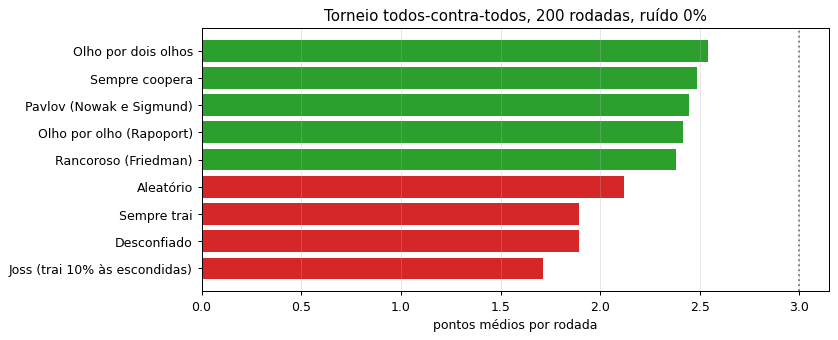

In [29]:
# 🏆 Torneio de Axelrod (1980/1984): qual estratégia vence o Dilema do Prisioneiro REPETIDO?
T, R, P, S = 5, 3, 1, 0            # Tentação > Recompensa > Punição > Otário (valores de Axelrod)
PAGAMENTO = {('C', 'C'): (R, R), ('C', 'D'): (S, T), ('D', 'C'): (T, S), ('D', 'D'): (P, P)}

# Cada estratégia recebe (meu histórico, histórico do oponente, gerador aleatório) e devolve 'C' (coopera) ou 'D' (trai)
ESTRATEGIAS_DP = {
    'Olho por olho (Rapoport)': lambda eu, ele, r: 'C' if not ele else ele[-1],
    'Olho por dois olhos':      lambda eu, ele, r: 'D' if ele[-2:] == ['D', 'D'] else 'C',
    'Rancoroso (Friedman)':     lambda eu, ele, r: 'D' if 'D' in ele else 'C',
    'Pavlov (Nowak e Sigmund)': lambda eu, ele, r: 'C' if not eu else (eu[-1] if ele[-1] == 'C' else ('D' if eu[-1] == 'C' else 'C')),
    'Sempre coopera':           lambda eu, ele, r: 'C',
    'Sempre trai':              lambda eu, ele, r: 'D',
    'Desconfiado':              lambda eu, ele, r: 'D' if not ele else ele[-1],
    'Joss (trai 10% às escondidas)': lambda eu, ele, r: 'D' if r.random() < 0.1 else ('C' if not ele else ele[-1]),
    'Aleatório':                lambda eu, ele, r: r.choice('CD'),
}

def partida(e1, e2, rodadas=200, ruido=0.0, semente=0):
    r = random.Random(semente)
    h1, h2, p1, p2 = [], [], 0, 0
    for _ in range(rodadas):
        a, b = e1(h1, h2, r), e2(h2, h1, r)
        if r.random() < ruido: a = 'D' if a == 'C' else 'C'      # ruído: a ação sai trocada ("mal-entendido")
        if r.random() < ruido: b = 'D' if b == 'C' else 'C'
        g1, g2 = PAGAMENTO[(a, b)]
        h1.append(a); h2.append(b); p1 += g1; p2 += g2
    return p1 / rodadas, p2 / rodadas

def torneio(ruido=0.0):
    nomes = list(ESTRATEGIAS_DP)
    M = np.zeros((len(nomes), len(nomes)))                      # M[i, j] = pontos médios de i contra j
    for i, j in itertools.combinations_with_replacement(range(len(nomes)), 2):
        a, b = partida(ESTRATEGIAS_DP[nomes[i]], ESTRATEGIAS_DP[nomes[j]], ruido=ruido, semente=i * 31 + j)
        M[i, j], M[j, i] = a, b
    return nomes, M

def mostrar_torneio(ruido=0.0):
    nomes, M = torneio(ruido)
    media = M.mean(axis=1)
    ordem = np.argsort(media)
    print(f'Ruído = {ruido:.0%}. Pontos médios por rodada (máx. 5; cooperação mútua = 3):\n')
    for pos, i in enumerate(ordem[::-1], 1):
        print(f'  {pos}º  {nomes[i]:<32} {media[i]:.2f}')
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.barh([nomes[i] for i in ordem], media[ordem],
            color=[CORES['verde'] if media[i] >= np.median(media) else CORES['vermelho'] for i in ordem])
    ax.axvline(3, ls=':', color='gray'); ax.set_xlabel('pontos médios por rodada')
    ax.set_title(f'Torneio todos-contra-todos, 200 rodadas, ruído {ruido:.0%}'); ax.grid(axis='x', alpha=0.3)
    plt.show()
    return nomes, M

nomes_dp, M_dp = mostrar_torneio(0.0)


#### 🔎 Como interpretar o resultado

- **As 5 primeiras colocadas são todas "gentis"** (nunca traem primeiro). As 4 últimas traem primeiro em algum momento. Axelrod observou exatamente isso: no 1º torneio, as 8 melhores estratégias eram gentis.
- **"Olho por dois olhos" venceu e "Olho por olho" ficou em 4º.** Axelrod notou que o "Olho por dois olhos" **teria vencido** o primeiro torneio se tivesse sido inscrito, por ser **mais tolerante**. No segundo torneio, porém, ele foi inscrito e foi mal, porque os participantes já sabiam disso e enviaram estratégias que o **exploravam** (traindo uma vez sim, outra não). **O melhor depende de quem são os outros.**
- **"Sempre coopera" ficou em 2º.** Parece contradizer a ideia de que é preciso saber retaliar, mas ele só foi bem porque **há poucos exploradores** neste torneio. O próximo experimento mostra o que acontece quando há muitos ingênuos.
- **"Joss" ficou em último:** as traições "espertas" geram retaliação, e a partida contra o "Olho por olho" vira uma sequência de vinganças mútuas.
- Axelrod resumiu as **4 qualidades** das estratégias vencedoras: ser **gentil** (não trair primeiro), **retaliadora** (responder à traição), **perdoadora** (voltar a cooperar quando o outro volta) e **clara** (fácil de entender pelo outro).
- **Na vida real:** a reputação de vendedores no Mercado Livre, as notas de motoristas de aplicativo e os contratos de longo prazo entre empresas funcionam porque transformam um jogo de **uma rodada** (em que trair compensa) em um jogo **repetido** (em que a cooperação se sustenta). Axelrod chamou isso de **"sombra do futuro"**.

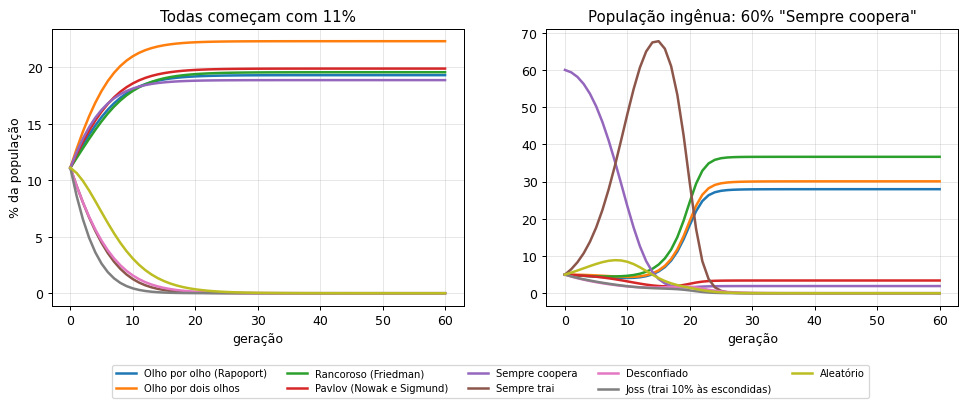

Todas começam com 11%  (início → pico na geração → geração 60)
  Olho por dois olhos               11.1% →  22.3% (60) →  22.3%
  Pavlov (Nowak e Sigmund)          11.1% →  19.9% (60) →  19.9%
  Rancoroso (Friedman)              11.1% →  19.6% (60) →  19.6%
  Olho por olho (Rapoport)          11.1% →  19.3% (60) →  19.3%
  Sempre coopera                    11.1% →  18.9% (60) →  18.9%

População ingênua: 60% "Sempre coopera"  (início → pico na geração → geração 60)
  Sempre trai                        5.0% →  67.7% (15) →   0.0%
  Sempre coopera                    60.0% →  60.0% ( 0) →   1.9%
  Rancoroso (Friedman)               5.0% →  36.7% (45) →  36.7%
  Olho por dois olhos                5.0% →  30.1% (60) →  30.1%
  Olho por olho (Rapoport)           5.0% →  28.0% (60) →  28.0%



In [30]:
# 🧬 Torneio ecológico: quem pontua mais "tem mais filhos" na geração seguinte (dinâmica do replicador)
def ecologia(M, pop, geracoes=60):
    hist = [pop]
    for _ in range(geracoes):
        aptidao = M @ pop                                        # pontos médios contra a população ATUAL
        pop = pop * aptidao / (pop @ aptidao)                    # cresce quem está acima da média
        hist.append(pop)
    return np.array(hist)

k = len(nomes_dp)
iguais = np.ones(k) / k
ingenua = np.full(k, 0.4 / (k - 1)); ingenua[nomes_dp.index('Sempre coopera')] = 0.6   # 60% de ingênuos
cenarios_eco = {'Todas começam com 11%': ecologia(M_dp, iguais),
                'População ingênua: 60% "Sempre coopera"': ecologia(M_dp, ingenua)}

fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, (titulo, hist) in zip(axs, cenarios_eco.items()):
    for i, nome in enumerate(nomes_dp):
        ax.plot(100 * hist[:, i], lw=2, color=plt.cm.tab10(i), label=nome)
    ax.set_title(titulo); ax.set_xlabel('geração'); ax.grid(alpha=0.3)
axs[0].set_ylabel('% da população')
fig.legend(nomes_dp, loc='lower center', ncol=5, fontsize=8, bbox_to_anchor=(0.5, -0.16))
plt.show()

for titulo, hist in cenarios_eco.items():
    print(f'{titulo}  (início → pico na geração → geração 60)')
    for i in np.argsort(-hist[:, :].max(axis=0))[:5]:
        print(f'  {nomes_dp[i]:<32} {100 * hist[0, i]:5.1f}% → {100 * hist[:, i].max():5.1f}% ({hist[:, i].argmax():2d}) → {100 * hist[-1, i]:5.1f}%')
    print()


#### 🔎 Como interpretar os gráficos

Na **dinâmica do replicador**, a fatia de cada estratégia cresce na proporção em que seus pontos ficam acima da média da população, como "filhos" proporcionais ao sucesso.

- **Esquerda (todas começam iguais, com 11%):** as quatro estratégias que traem primeiro **desaparecem em cerca de 20 gerações**. As gentis dividem a população (de 19% a 22% cada). Sem ninguém para explorar, todas cooperam e ganham 3 pontos por rodada.
- **Direita (60% de ingênuos "Sempre coopera"):** aqui está a lição mais importante.
  - **"Sempre trai" explode**: vai de 5% para **68% da população na geração 15**, explorando os ingênuos;
  - os ingênuos caem de 60% para 1,9%;
  - quando acabam os ingênuos, **"Sempre trai" fica sem quem explorar** e passa a jogar contra si mesmo (1 ponto por rodada) e contra retaliadores. **Desaparece por volta da geração 25**;
  - quem herda a população são os **retaliadores gentis**: Rancoroso (37%), Olho por dois olhos (30%) e Olho por olho (28%).
- Axelrod descreveu exatamente esse padrão: **estratégias exploradoras destroem a própria fonte de lucro**. É a dinâmica de um predador que extingue a presa.
- **Moral para quem projeta agentes:** um agente que só coopera é **explorável** e precisa da proteção de outros. Um agente que só explora prospera no curto prazo e fracassa no longo. A cooperação estável precisa de **retaliação**.

In [14]:
# 🎛️ E se houver mal-entendidos? Aumente o ruído e veja o "Olho por olho" perder força (Wu e Axelrod, 1995)
interact(lambda ruido: mostrar_torneio(ruido) and None,
         ruido=widgets.FloatSlider(value=0.05, min=0, max=0.2, step=0.01, readout_format='.0%', description='ruído'));


interactive(children=(FloatSlider(value=0.05, description='ruído', max=0.2, readout_format='.0%', step=0.01), …

#### 🔎 Como usar e interpretar

O **ruído** é a probabilidade de uma ação sair trocada: o agente queria cooperar, mas a mensagem chegou como traição (uma falha de rede, um mal-entendido, uma entrega atrasada que parecia descaso).

| Ruído | 1º lugar | Posição do "Olho por olho" |
|:-:|---|:-:|
| 0% | Olho por dois olhos (2,54) | 4º (2,42) |
| 5% | Olho por dois olhos (2,25) | 5º (2,11) |
| 10% | Pavlov (2,23) | 8º (2,10) |

- **Com ruído, o "Olho por olho" sofre o efeito eco:** uma traição acidental gera uma retaliação, que gera outra retaliação... e os dois ficam alternando vinganças até que outro erro quebre o ciclo.
- **Estratégias mais tolerantes (Olho por dois olhos) ou que "pedem desculpas" (Pavlov) resistem melhor**, como mostraram **Nowak e Sigmund** (1993) e **Wu e Axelrod** (1995).
- **Lição prática:** em sistemas distribuídos reais, mensagens se perdem e atrasam. Agentes que punem **toda** falha aparente entram em conflito à toa; é preciso alguma **tolerância** (por exemplo, tentar de novo antes de concluir que o outro "traiu").

### 6.5 📚 Quando dois robôs "conversam" pelo mercado: o livro de US$ 23 milhões

Em abril de 2011, o biólogo **Michael Eisen** reparou que um livro técnico sobre o desenvolvimento das moscas, *The Making of a Fly*, de Peter Lawrence, estava à venda na Amazon por **US$ 1,7 milhão** e por **US$ 2,2 milhões**, em dois vendedores diferentes. Nos dias seguintes, os preços **subiram todos os dias**, até passar de **US$ 23,6 milhões**. Eisen descobriu a razão comparando os preços diariamente (Eisen, 2011):

- o vendedor A ajustava seu preço para **0,9983 × o preço do B** (ficar um pouquinho mais barato e aparecer primeiro);
- o vendedor B ajustava o seu para **1,270589 × o preço do A** (provavelmente nem tinha o livro: se alguém comprasse, ele compraria do A e revenderia com lucro, apostando na sua boa reputação).

Cada regra, **sozinha**, faz sentido. O que acontece quando as duas interagem?

Crescimento por dia: 0.9983 × 1.270589 = 1.2684 (+26.8% ao dia)
Partindo de US$ 35,54, o robô A passa de US$ 23.698.655,93 (o recorde real) no dia 58.
Com trava de 3× o preço de referência, o preço máximo fica em US$ 106.62.


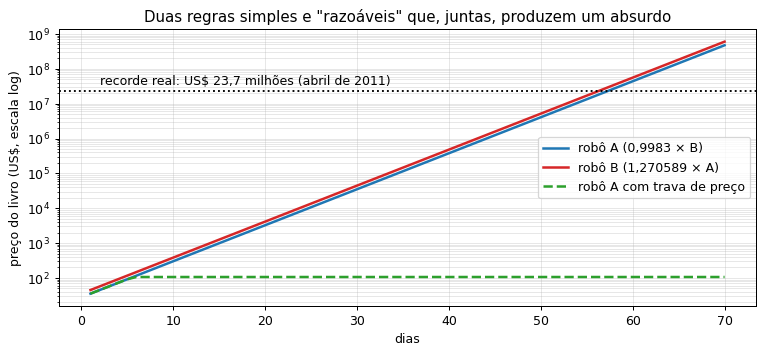

In [15]:
# 📚 Dois robôs de preço que "conversam" pelo mercado: o livro de US$ 23,7 milhões (Eisen, 2011)
FATOR_A = 0.9983      # robô A: "cobre 0,17% a MENOS que o concorrente" (para aparecer primeiro na busca)
FATOR_B = 1.270589    # robô B: "cobre 27% a MAIS que o concorrente" (ele nem tem o livro; se vender, compra do A)

def simular_precos(dias, teto=None, inicial=35.54):
    a, b, hist = inicial, inicial, []
    for _ in range(dias):
        a = FATOR_A * b                              # uma vez por dia, cada robô olha o preço do outro
        b = FATOR_B * a
        if teto is not None:                          # trava de segurança (guardrail)
            a, b = min(a, teto), min(b, teto * FATOR_B)
        hist.append((a, b))
    return np.array(hist)

dias = 70
h = simular_precos(dias)
h_trava = simular_precos(dias, teto=3 * 35.54)
dia_recorde = int(np.argmax(h[:, 0] >= 23_698_655.93)) + 1
print(f'Crescimento por dia: {FATOR_A} × {FATOR_B} = {FATOR_A * FATOR_B:.4f} (+{100 * (FATOR_A * FATOR_B - 1):.1f}% ao dia)')
print(f'Partindo de US$ 35,54, o robô A passa de US$ 23.698.655,93 (o recorde real) no dia {dia_recorde}.')
print(f'Com trava de 3× o preço de referência, o preço máximo fica em US$ {h_trava[:, 0].max():.2f}.')

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(range(1, dias + 1), h[:, 0], color=CORES['azul'], lw=2, label='robô A (0,9983 × B)')
ax.semilogy(range(1, dias + 1), h[:, 1], color=CORES['vermelho'], lw=2, label='robô B (1,270589 × A)')
ax.semilogy(range(1, dias + 1), h_trava[:, 0], color=CORES['verde'], lw=2, ls='--', label='robô A com trava de preço')
ax.axhline(23_698_655.93, ls=':', color='black'); ax.text(2, 3.5e7, 'recorde real: US$ 23,7 milhões (abril de 2011)')
ax.set_xlabel('dias'); ax.set_ylabel('preço do livro (US$, escala log)')
ax.set_title('Duas regras simples e "razoáveis" que, juntas, produzem um absurdo')
ax.legend(loc='center right'); ax.grid(alpha=0.3, which='both'); plt.show()


#### 🔎 Como interpretar o resultado

- **A cada dia o preço é multiplicado por 0,9983 × 1,270589 ≈ 1,268**, ou seja, cresce **26,8% ao dia**, de forma exponencial. Na escala logarítmica do gráfico, isso aparece como uma **reta**.
- **Partindo de um preço normal (US$ 35,54), o recorde real de US$ 23,7 milhões é atingido em 58 dias.** Nenhum dos dois programadores escreveu "cobre 23 milhões por um livro". O absurdo é um **comportamento emergente** da interação entre dois agentes simples.
- **A trava de segurança resolve:** com um teto de 3× o preço de referência, o preço para em **US$ 106,62**. Isso é um *guardrail*: um limite que o agente **nunca** ultrapassa, por mais "lógica" que pareça a regra.
- **Por que isso importa:**
  - O **Flash Crash** de 6 de maio de 2010 derrubou o índice Dow Jones em quase mil pontos em minutos; parte da explicação envolve robôs de alta frequência **reagindo uns aos outros** (Kirilenko et al., 2017).
  - **Calvano et al.** (2020) mostraram que agentes de **aprendizado por reforço** encarregados de definir preços **aprenderam sozinhos a manter preços altos**, punindo quem baixava o preço, **sem nunca trocar mensagens**: um conluio algorítmico. Um estudo com postos de gasolina na Alemanha encontrou margens maiores onde os concorrentes adotaram precificação algorítmica (Assad et al., 2024). Órgãos de defesa da concorrência no mundo todo discutem como lidar com isso.
- **Lição de projeto:** teste seu agente **contra outros agentes**, não só contra um ambiente fixo; coloque limites explícitos; e monitore o sistema **como um todo**, porque a falha pode não estar em nenhum agente isolado, e sim na interação entre eles.

### 6.6 🎣 Tragédia dos comuns × gestão comunitária

**Garrett Hardin** (1968) popularizou um argumento de **William Lloyd** (1833): se um pasto é de todos, cada pastor ganha **sozinho** com cada ovelha a mais, mas o prejuízo do pasto degradado é **dividido** entre todos. O resultado previsto é a ruína do recurso. Hardin concluiu que só havia duas saídas: **privatizar** ou deixar o **Estado** regular.

**Elinor Ostrom** (1990) estudou comunidades reais (pescadores, irrigação, florestas) e mostrou uma **terceira saída**: os próprios usuários criam e fiscalizam regras de uso. Ela identificou **princípios** comuns às comunidades bem-sucedidas, entre eles: limites claros de quem pode usar o recurso, regras adaptadas ao local, participação dos usuários na criação das regras, **monitoramento** e **sanções graduais** para quem descumpre. Ostrom foi a primeira mulher a receber o Nobel de Economia (2009).

Vamos simular **10 pescadores** dividindo um lago com capacidade para 1.000 t de peixes, que se reproduzem em crescimento logístico (taxa de 25% ao ano). O **rendimento máximo sustentável** é 62,5 t/ano: pescando menos do que isso, o lago se recupera.

Rendimento máximo sustentável: 62.5 t/ano

Cenário                                        pedido/ano  estoque final  pesca em 60 anos  por pescador
Livre acesso: cada um pesca 15 t/ano                150 t            0 t            1148 t         115 t
Cota de 5 t/ano cada + defeso abaixo de 30%          50 t          774 t            3000 t         300 t
Cota, mas 3 "caronas" pescam 15 t/ano                80 t            0 t            2268 t         227 t


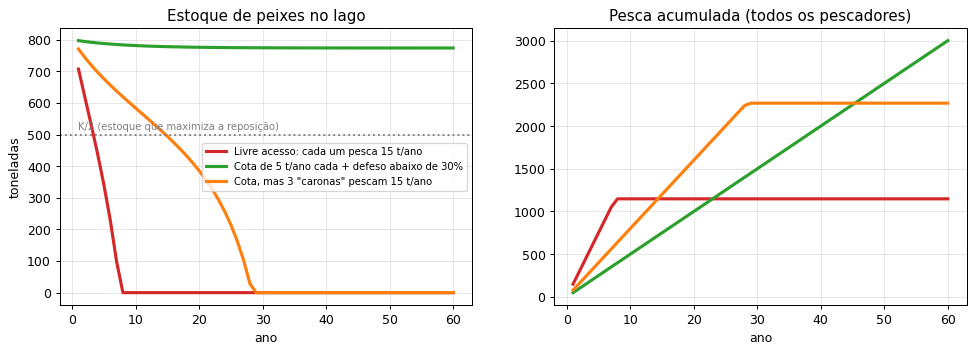

In [31]:
# 🎣 Tragédia dos comuns (Hardin, 1968) × gestão comunitária (Ostrom, 1990): 10 pescadores dividem um lago
K, r_cresc, N_PESC, ANOS = 1000, 0.25, 10, 60      # capacidade do lago (t), taxa de reprodução, pescadores, anos
RMS = r_cresc * K / 4                              # rendimento máximo sustentável = 62,5 t/ano (quando o estoque = K/2)

def simular_lago(pedidos_por_pescador, defeso=None):
    estoque, hist_estoque, hist_pesca = 800.0, [], []
    for _ in range(ANOS):
        pedido = sum(pedidos_por_pescador)
        if defeso is not None and estoque < defeso * K:      # regra da comunidade: abaixo do limite, ninguém pesca
            pedido = 0
        pesca = min(pedido, estoque)
        estoque = estoque - pesca
        estoque += r_cresc * estoque * (1 - estoque / K)     # crescimento logístico
        hist_estoque.append(estoque); hist_pesca.append(pesca)
    return np.array(hist_estoque), np.array(hist_pesca)

cenarios = {
    'Livre acesso: cada um pesca 15 t/ano':         ([15] * N_PESC, None),
    'Cota de 5 t/ano cada + defeso abaixo de 30%':  ([5] * N_PESC, 0.3),
    'Cota, mas 3 "caronas" pescam 15 t/ano':        ([5] * 7 + [15] * 3, None),
}
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
print(f'Rendimento máximo sustentável: {RMS:.1f} t/ano\n')
print(f'{"Cenário":<46}{"pedido/ano":>11}{"estoque final":>15}{"pesca em 60 anos":>18}{"por pescador":>14}')
for (nome, (pedidos, defeso)), cor in zip(cenarios.items(), [CORES['vermelho'], CORES['verde'], CORES['laranja']]):
    est, pesca = simular_lago(pedidos, defeso)
    axs[0].plot(range(1, ANOS + 1), est, color=cor, lw=2.5, label=nome)
    axs[1].plot(range(1, ANOS + 1), np.cumsum(pesca), color=cor, lw=2.5)
    print(f'{nome:<46}{sum(pedidos):>9} t{est[-1]:>13.0f} t{pesca.sum():>16.0f} t{pesca.sum() / N_PESC:>12.0f} t')
axs[0].axhline(K / 2, ls=':', color='gray'); axs[0].text(1, K / 2 + 15, 'K/2 (estoque que maximiza a reposição)', color='gray', fontsize=8)
axs[0].set_title('Estoque de peixes no lago'); axs[0].set_xlabel('ano'); axs[0].set_ylabel('toneladas')
axs[1].set_title('Pesca acumulada (todos os pescadores)'); axs[1].set_xlabel('ano')
axs[0].legend(fontsize=8); [ax.grid(alpha=0.3) for ax in axs]; plt.show()


#### 🔎 Como interpretar o resultado

- **Livre acesso (vermelho):** cada um pesca 15 t/ano. Individualmente parece pouco, mas o total, **150 t/ano**, é mais que o dobro do que o lago repõe. O estoque **colapsa no 8º ano** e a pesca acumulada para em 1.148 t, para sempre.
- **Cota + defeso (verde):** cada um pesca 5 t/ano (50 t no total, abaixo das 62,5 t sustentáveis), e todos param se o estoque cair abaixo de 30%. O estoque **se estabiliza em 774 t** e a pesca continua indefinidamente: **3.000 t em 60 anos**, quase o triplo do livre acesso. Repare no gráfico da direita: a curva verde começa **mais baixa** que a vermelha. **Cooperar custa no curto prazo e compensa no longo.**
- **Cota com 3 "caronas" (laranja):** 7 pescadores respeitam a cota e 3 pescam 15 t/ano. O total, 80 t/ano, passa do limite sustentável, e o lago colapsa mais devagar, **no 29º ano**. Durante esse tempo, cada carona pescou o triplo de cada pescador honesto; no fim, ninguém pesca mais nada. Sem **monitoramento e sanção** (os princípios de Ostrom), poucos aproveitadores bastam para destruir o recurso de todos.
- **Exemplos reais:**
  - **Seguro-defeso** (Lei 10.779/2003): o Brasil paga ao pescador artesanal um salário mínimo mensal durante o período de reprodução dos peixes, quando a pesca é proibida. É uma regra de coordenação **com compensação** para quem coopera.
  - **Manejo comunitário do pirarucu** na Amazônia (como na Reserva de Mamirauá): comunidades contam os peixes, definem cotas e vigiam os lagos; os estoques de pirarucu se recuperaram onde o manejo foi adotado (Castello et al., 2009).
  - **Controle de congestionamento do TCP:** em 1986 a internet sofreu um "colapso de congestionamento": todos retransmitiam ao mesmo tempo e a vazão útil despencou. **Van Jacobson** (1988) propôs que cada computador **reduza voluntariamente** o ritmo de envio quando detecta perda de pacotes. Bilhões de dispositivos seguem essa "norma social" até hoje, e a internet não colapsa. É uma solução distribuída para uma tragédia dos comuns, a mesma lógica da cota.

### 6.7 🐦 Coordenação emergente: Boids

**Craig Reynolds** (1987) queria animar bandos de pássaros para filmes sem programar a trajetória de cada um. Sua solução: cada "boid" segue **três regras locais**, olhando só os vizinhos próximos:

1. **Separação:** afaste-se de quem está perto demais;
2. **Alinhamento:** voe na direção média dos vizinhos;
3. **Coesão:** aproxime-se do centro dos vizinhos.

Não há líder, nem mapa, nem plano global. A técnica foi usada em filmes como *Batman: o Retorno* (1992) e rendeu a Reynolds um prêmio técnico da Academia de Cinema em 1998. Também inspirou a **Otimização por Enxame de Partículas** (Kennedy e Eberhart, 1995), tema da Aula 14.

Medimos a **ordem do bando**: o tamanho do vetor médio das direções de voo (0 = cada um para um lado; 1 = todos na mesma direção).

In [32]:
# 🎬 ANIMAÇÃO — Boids (Reynolds, 1987): um bando surge de 3 regras LOCAIS, sem líder e sem plano global
rng = np.random.default_rng(1)
N_BOIDS, LADO, RAIO, VELOCIDADE = 50, 100.0, 15.0, 1.5
pos_b = rng.uniform(0, LADO, (N_BOIDS, 2))
vel_b = rng.uniform(-1, 1, (N_BOIDS, 2))

def passo_boids(pos, vel, w_sep=1.0, w_ali=0.1, w_coe=0.01):
    dif = pos[None, :, :] - pos[:, None, :]
    dif = (dif + LADO / 2) % LADO - LADO / 2                       # mundo "toroidal": sai de um lado, entra do outro
    dist = np.linalg.norm(dif, axis=2) + np.eye(len(pos)) * 1e9
    viz = dist < RAIO                                              # cada boid só enxerga os vizinhos próximos
    tem_viz = viz.any(axis=1, keepdims=True)
    n_viz = np.maximum(viz.sum(axis=1, keepdims=True), 1)
    perto = dist < RAIO / 3
    separacao = -(dif / dist[:, :, None] ** 2 * perto[:, :, None]).sum(axis=1)   # 1) afaste-se de quem está perto demais
    alinhamento = (viz @ vel) / n_viz - vel                                      # 2) voe na direção média dos vizinhos
    coesao = (dif * viz[:, :, None]).sum(axis=1) / n_viz                         # 3) vá para o centro dos vizinhos
    vel = vel + w_sep * separacao + (w_ali * alinhamento + w_coe * coesao) * tem_viz
    vel = vel / np.linalg.norm(vel, axis=1, keepdims=True) * VELOCIDADE          # velocidade constante
    return (pos + vel) % LADO, vel

def ordem_do_bando(vel):
    # 1 = todos na mesma direção; perto de 0 = cada um para um lado
    return np.linalg.norm((vel / np.linalg.norm(vel, axis=1, keepdims=True)).mean(axis=0))

historico_boids = []
p, v = pos_b.copy(), vel_b.copy()
for t in range(300):
    if t % 5 == 0:
        historico_boids.append((p.copy(), v.copy()))
    p, v = passo_boids(p, v)
print(f'Ordem do bando (0 = caos, 1 = todos alinhados): início {ordem_do_bando(vel_b):.2f} → '
      f'passo 50: {ordem_do_bando(historico_boids[10][1]):.2f} → passo 100: {ordem_do_bando(historico_boids[20][1]):.2f} → '
      f'passo 300: {ordem_do_bando(v):.2f}')

fig, ax = plt.subplots(figsize=(5, 5), dpi=72)
def quadro_boids(k):
    ax.clear()
    pp, vv = historico_boids[k]
    ax.quiver(pp[:, 0], pp[:, 1], vv[:, 0], vv[:, 1], color=CORES['azul'], angles='xy', scale=30, width=0.008)
    ax.set_xlim(0, LADO); ax.set_ylim(0, LADO); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'passo {5 * k} · ordem = {ordem_do_bando(vv):.2f}')

anim = animation.FuncAnimation(fig, quadro_boids, frames=range(0, len(historico_boids), 2), interval=150)
mostrar_animacao(anim)


Ordem do bando (0 = caos, 1 = todos alinhados): início 0.01 → passo 50: 0.31 → passo 100: 0.79 → passo 300: 1.00


#### 🔎 Como interpretar a animação

- **A ordem vai de 0,01 (caos total) para 0,31 no passo 50, 0,79 no passo 100 e 1,00 no passo 300.** No começo, cada boid voa para um lado; aos poucos formam-se **pequenos grupos** alinhados, os grupos se encontram e se fundem, e no fim **o bando inteiro voa junto**.
- **Nenhuma linha de código diz "forme um bando".** O bando é uma propriedade **emergente**: existe no nível do grupo, mas não em nenhum indivíduo. É a mesma ideia dos autômatos celulares (Aula 13).
- **Aplicações reais:**
  - **Enxames de drones:** Vásárhelyi et al. (2018) fizeram 30 drones voarem juntos ao ar livre, sem controle central, com regras do tipo boids. Atenção: os grandes **shows de drones** com milhares de luzes normalmente usam trajetórias **pré-planejadas** por um computador central, não regras emergentes.
  - **Robótica de enxame:** os **Kilobots** de Harvard, mil robôs baratos que formam figuras usando só a comunicação com os vizinhos (Rubenstein, Cornejo e Nagpal, 2014).
  - **Multidões em filmes e jogos:** batalhas com milhares de personagens e simulação de evacuação de estádios e prédios.
- **Experimente:** mude os pesos em `passo_boids` (por exemplo, `w_ali=0` sem alinhamento, ou `w_sep=0` sem separação) e rode de novo. Sem alinhamento, os boids se aglomeram mas não voam juntos; sem separação, colapsam em um ponto.

### 6.8 🏘️ Segregação de Schelling: micromotivos e macrocomportamento

Em 1971, o economista **Thomas Schelling** fez um experimento usando moedas sobre um tabuleiro de xadrez. Dois tipos de moeda (aqui, laranja e azul) ocupam as casas, com algumas vazias. Cada moeda tem uma exigência **modesta**: quer que pelo menos uma fração dos vizinhos seja do **mesmo tipo**. Se não estiver satisfeita, muda para uma casa vazia. Schelling recebeu o Nobel de Economia em 2005, e esse é um dos modelos baseados em agentes mais famosos da história (Schelling, 1971, 1978).

In [ ]:
# 🎛️ Modelo de segregação de Schelling (1971): preferências LEVES geram bairros MUITO separados
def schelling(tolerancia=0.3, lado=30, vazio=0.1, iteracoes=60, semente=0):
    rng = np.random.default_rng(semente)
    grade = rng.choice([0, 1, 2], size=(lado, lado), p=[vazio, (1 - vazio) / 2, (1 - vazio) / 2])  # 0 = casa vazia
    def fracao_iguais(g):
        iguais, vizinhos = np.zeros(g.shape), np.zeros(g.shape)
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                if di == dj == 0: continue
                v = np.roll(np.roll(g, di, 0), dj, 1)
                iguais += (v == g) & (g > 0)
                vizinhos += (v > 0)
        return np.where(vizinhos > 0, iguais / np.maximum(vizinhos, 1), 1.0)
    inicial = grade.copy()
    for it in range(iteracoes):
        f = fracao_iguais(grade)
        insatisfeitos = np.argwhere((grade > 0) & (f < tolerancia))
        if len(insatisfeitos) == 0: break
        vazias = np.argwhere(grade == 0)
        rng.shuffle(vazias)
        for (i, j), (vi, vj) in zip(insatisfeitos, vazias):          # cada insatisfeito muda para uma casa vazia
            grade[vi, vj], grade[i, j] = grade[i, j], 0
    return inicial, grade, fracao_iguais, it

def mostrar_schelling(tolerancia=0.3):
    inicial, final, fracao_iguais, it = schelling(tolerancia)
    sim_ini = fracao_iguais(inicial)[inicial > 0].mean()
    sim_fim = fracao_iguais(final)[final > 0].mean()
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.8))
    cm = plt.matplotlib.colors.ListedColormap(['white', CORES['laranja'], CORES['azul']])
    for ax, g, titulo, s in [(axs[0], inicial, 'Início (aleatório)', sim_ini), (axs[1], final, f'Depois de {it} rodadas', sim_fim)]:
        ax.imshow(g, cmap=cm, vmin=0, vmax=2); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'{titulo}\nvizinhos parecidos com você: {s:.0%}')
    plt.suptitle(f'Cada morador só quer que pelo menos {tolerancia:.0%} dos vizinhos sejam parecidos com ele'); plt.show()
    print(f'Exigência individual: {tolerancia:.0%} → resultado coletivo: {sim_fim:.0%} de vizinhos iguais (começou em {sim_ini:.0%})')

interact(mostrar_schelling, tolerancia=widgets.FloatSlider(value=0.3, min=0.1, max=0.8, step=0.05,
                                                           readout_format='.0%', description='exigência'));


interactive(children=(FloatSlider(value=0.3, description='exigência', max=0.8, min=0.1, readout_format='.0%', …

In [19]:
# Tabela para comparar várias exigências de uma vez (a mesma simulação, sem os gráficos)
print(f'{"exigência individual":>22}{"vizinhos iguais no fim":>26}{"rodadas":>9}')
for tol in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    ini, fim, fr, it = schelling(tol)
    print(f'{tol:>21.0%}{fr(fim)[fim > 0].mean():>25.0%}{it:>9}')


  exigência individual    vizinhos iguais no fim  rodadas
                  10%                      50%        1
                  20%                      56%        6
                  30%                      76%        8
                  40%                      82%       14
                  50%                      87%       20
                  60%                      94%       59
                  70%                      63%       59
                  80%                      49%       59


#### 🔎 Como usar e interpretar

Mova o controle e compare com a tabela gerada pela célula seguinte:

| Exigência individual | Vizinhos iguais no fim | O que acontece |
|:-:|:-:|---|
| 10%–20% | 50%–56% | Quase nada muda: a mistura aleatória já satisfaz quase todos |
| **30%** | **76%** | Cada um aceita ser **minoria** (até 70% de vizinhos diferentes), mas o resultado é um bairro com 3/4 de iguais |
| 50% | 87% | Exigência de "metade igual" gera bairros quase homogêneos |
| 60% | 94% | Segregação quase total |
| 70%–80% | 63% → 49% | Quase ninguém fica satisfeito; todos mudam o tempo todo e **o sistema nunca estabiliza** |

- **A lição de Schelling:** o resultado **coletivo** (76% de vizinhos iguais) é muito mais extremo do que a preferência de **qualquer indivíduo** (30%). Ninguém desejava bairros separados, e mesmo assim eles surgiram. Olhar só para as intenções individuais não permite prever o comportamento do grupo.
- **Cuidado com a interpretação:** o modelo mostra que preferências leves **bastam** para gerar segregação, **não** que elas sejam a causa da segregação em cidades reais. Renda, preço dos imóveis, discriminação e políticas públicas também pesam. Um modelo baseado em agentes **gera hipóteses**; os dados reais é que as testam.
- **Outros contextos:** a mesma dinâmica ajuda a pensar **bolhas** em redes sociais (seguir quem pensa parecido e deixar de seguir quem discorda), a formação de grupos em salas de aula e a concentração de empresas em polos regionais.

## 7. Decisão coletiva: quando os agentes precisam votar

Muitos sistemas multiagentes precisam tomar **uma** decisão a partir de **muitas** preferências: um comitê de classificadores de ML votando um rótulo, sensores divergentes votando qual leitura aceitar, robôs escolhendo para qual objetivo ir juntos. A área que estuda isso é a **escolha social computacional** (Brandt et al., 2016).

A má notícia veio cedo:
- **Condorcet** (1785) mostrou que a preferência de um grupo pode ser **cíclica** mesmo quando a de cada membro é coerente;
- **Kenneth Arrow** (1951) provou que, com 3 ou mais opções, **nenhuma** regra de votação satisfaz ao mesmo tempo um pequeno conjunto de critérios razoáveis de justiça (teorema da impossibilidade; Nobel de 1972);
- **Gibbard** (1973) e **Satterthwaite** (1975) provaram que toda regra razoável com 3 ou mais opções pode ser **manipulada** por algum eleitor que mente sobre suas preferências.

Na prática: **a regra de votação escolhida pode decidir o resultado**. Veja com uma turma de 19 alunos escolhendo o lugar da confraternização.

In [20]:
# 🗳️ Onde será a confraternização da turma? As MESMAS preferências, regras diferentes, vencedores diferentes
perfil = [  # (ordem de preferência, nº de alunos)
    (['Pizzaria', 'Japonês', 'Churrascaria'], 8),
    (['Churrascaria', 'Japonês', 'Pizzaria'], 6),
    (['Japonês', 'Churrascaria', 'Pizzaria'], 5),
]
opcoes = perfil[0][0]

def pluralidade(perfil):
    c = Counter()
    for ordem, n in perfil: c[ordem[0]] += n
    return c

def dois_turnos(perfil):            # como nas eleições brasileiras para presidente
    c = pluralidade(perfil)
    finalistas = [o for o, _ in c.most_common(2)]
    seg = Counter()
    for ordem, n in perfil:
        seg[min(finalistas, key=ordem.index)] += n
    return c, seg

def borda(perfil):                  # Borda (1781): 1º lugar vale 2 pontos, 2º vale 1, 3º vale 0
    c = Counter()
    for ordem, n in perfil:
        for pos, o in enumerate(ordem): c[o] += n * (len(ordem) - 1 - pos)
    return c

def confrontos(perfil):             # Condorcet (1785): quem vence TODOS os confrontos diretos?
    return {(a, b): sum(n for ordem, n in perfil if ordem.index(a) < ordem.index(b))
            for a, b in itertools.permutations(opcoes, 2)}

print(f'{sum(n for _, n in perfil)} alunos votando:')
for ordem, n in perfil: print(f'  {n} alunos: ' + ' > '.join(ordem))

p = pluralidade(perfil)
print(f'\n1) Maioria simples (pluralidade): {dict(p)}  →  vence {p.most_common(1)[0][0]}')
t1, t2 = dois_turnos(perfil)
print(f'2) Dois turnos: 2º turno {dict(t2)}  →  vence {t2.most_common(1)[0][0]}')
b = borda(perfil)
print(f'3) Contagem de Borda: {dict(b)}  →  vence {b.most_common(1)[0][0]}')
cf = confrontos(perfil)
print('4) Confrontos diretos (Condorcet):')
for a, bb in itertools.combinations(opcoes, 2):
    print(f'     {a} {cf[(a, bb)]} × {cf[(bb, a)]} {bb}  →  {a if cf[(a, bb)] > cf[(bb, a)] else bb}')
vencedor_c = [a for a in opcoes if all(cf[(a, o)] > cf[(o, a)] for o in opcoes if o != a)]
print(f'   Vencedor de Condorcet: {vencedor_c[0] if vencedor_c else "nenhum"}')

print('\n🔄 Paradoxo de Condorcet com 3 amigos escolhendo o filme:')
ciclo = [(['Ação', 'Comédia', 'Terror'], 1), (['Comédia', 'Terror', 'Ação'], 1), (['Terror', 'Ação', 'Comédia'], 1)]
opcoes_ciclo = ciclo[0][0]
for a, bb in [('Ação', 'Comédia'), ('Comédia', 'Terror'), ('Terror', 'Ação')]:
    va = sum(n for o, n in ciclo if o.index(a) < o.index(bb))
    print(f'   {a} vence {bb} por {va} × {3 - va}')
print('   → a "preferência do grupo" anda em círculo: não existe uma opção favorita do grupo.')


19 alunos votando:
  8 alunos: Pizzaria > Japonês > Churrascaria
  6 alunos: Churrascaria > Japonês > Pizzaria
  5 alunos: Japonês > Churrascaria > Pizzaria

1) Maioria simples (pluralidade): {'Pizzaria': 8, 'Churrascaria': 6, 'Japonês': 5}  →  vence Pizzaria
2) Dois turnos: 2º turno {'Pizzaria': 8, 'Churrascaria': 11}  →  vence Churrascaria
3) Contagem de Borda: {'Pizzaria': 16, 'Japonês': 24, 'Churrascaria': 17}  →  vence Japonês
4) Confrontos diretos (Condorcet):
     Pizzaria 8 × 11 Japonês  →  Japonês
     Pizzaria 8 × 11 Churrascaria  →  Churrascaria
     Japonês 13 × 6 Churrascaria  →  Japonês
   Vencedor de Condorcet: Japonês

🔄 Paradoxo de Condorcet com 3 amigos escolhendo o filme:
   Ação vence Comédia por 2 × 1
   Comédia vence Terror por 2 × 1
   Terror vence Ação por 2 × 1
   → a "preferência do grupo" anda em círculo: não existe uma opção favorita do grupo.


#### 🔎 Como interpretar o resultado

**As mesmas preferências produziram três vencedores diferentes:**

| Regra | Vencedor | Por quê |
|---|---|---|
| Maioria simples | **Pizzaria** | Tem mais 1ºs lugares (8 de 19), embora 11 alunos a coloquem em **último** |
| Dois turnos (como na eleição presidencial brasileira, Constituição de 1988, art. 77) | **Churrascaria** | O Japonês, com só 5 votos, sai no 1º turno; no 2º, os eleitores do Japonês preferem a Churrascaria |
| Borda | **Japonês** | É o 2º lugar de quase todo mundo e soma mais pontos |
| Condorcet | **Japonês** | Vence **todos** os confrontos diretos: 11 × 8 contra a Pizzaria e 13 × 6 contra a Churrascaria |

- **O Japonês, que derrotaria qualquer adversário num confronto direto, foi eliminado no 1º turno.** Esse fenômeno ("espremido no centro") acontece em eleições reais com candidatos de consenso que têm poucos votos de 1ª preferência.
- **O paradoxo de Condorcet:** com os 3 amigos, Ação vence Comédia, Comédia vence Terror e Terror vence Ação, sempre por 2 × 1. Não existe "a opção preferida do grupo". Quem decide a **ordem** das votações decide o resultado: votando Ação × Comédia primeiro e o vencedor contra Terror, vence Terror; com outra ordem, vence outro filme.
- **Onde isso aparece em computação:**
  - **Ensembles** de aprendizado de máquina, como o *random forest* (Breiman, 2001), que decide por **maioria** entre centenas de árvores (Aula 06);
  - **Sistemas de recomendação** que agregam avaliações de muitos usuários;
  - **Agentes com LLM** que geram várias respostas e escolhem a mais votada (*self-consistency*), ou que debatem até convergir (Seção 8).

## 8. Sistemas multiagentes com LLMs: os agentes de IA de hoje

### 8.1 Do agente BDI ao agente com LLM

Desde 2023, "agente" voltou a ser uma palavra da moda, agora para sistemas em que um **modelo de linguagem** (LLM, Aula 09) decide quais ações tomar. O padrão básico é o ciclo **ReAct** (*Reason + Act*, Yao et al., 2023): o modelo alterna **pensamento** ("preciso saber o status do pedido"), **ação** (chamar a ferramenta `rastrear_pedido`) e **observação** (ler o resultado), até concluir a tarefa.

Os conceitos desta aula reaparecem com nomes novos:

| Conceito clássico de SMA | Equivalente nos agentes com LLM |
|---|---|
| Crenças (B) | Contexto da conversa, memória, documentos recuperados (RAG) |
| Desejos e intenções (D, I) | O objetivo dado no *prompt* e o plano/lista de tarefas que o modelo escreve |
| Sensores e atuadores | **Ferramentas**: APIs, buscas, bancos de dados, execução de código (padronizadas pelo MCP) |
| Ciclo perceber-deliberar-agir | Ciclo ReAct: pensamento → ação → observação |
| ACL e protocolos | Mensagens em linguagem natural ou JSON entre agentes (A2A) |
| Contract Net / gerente-contratados | Padrão **orquestrador-trabalhadores** |
| Estratégia de compromisso (Seção 2.9) | Quando o agente deve **replanejar**: cada replanejamento é uma chamada paga ao modelo |

### 8.2 Padrões de organização

Os padrões mais usados, descritos por **Anthropic** (2024, *Building effective agents*) e por frameworks como **AutoGen** (Wu et al., 2023):

| Padrão | Como funciona | Exemplo prático |
|---|---|---|
| **Cadeia (pipeline)** | A saída de um agente é a entrada do próximo | Extrair dados de um contrato → revisar → resumir para o cliente |
| **Roteamento** | Um agente classifica a tarefa e a envia ao especialista | Atendimento: financeiro, logística ou suporte técnico |
| **Orquestrador-trabalhadores** | Um agente divide a tarefa, delega a vários subagentes **em paralelo** e junta os resultados | Pesquisa profunda: cada subagente investiga um aspecto |
| **Avaliador-otimizador** | Um agente produz, outro critica, o primeiro corrige | Um agente escreve código, outro roda os testes e aponta os erros |
| **Debate** | Vários agentes respondem, criticam as respostas uns dos outros e convergem | Melhora a precisão em raciocínio e fatos (Du et al., 2024) |
| **Equipes com papéis** | Agentes com papéis de uma empresa (gerente, programador, testador) | **MetaGPT** (Hong et al., 2024) e **ChatDev** (Qian et al., 2024) geram software assim |
| **Simulação social** | Muitos agentes com personalidade e memória convivem num mundo virtual | *Generative Agents* (Park et al., 2023): 25 personagens organizaram sozinhos uma festa de Dia dos Namorados |

**Caso real:** a Anthropic (2025) descreveu seu sistema de **pesquisa multiagente**: um agente líder planeja a pesquisa e cria subagentes que buscam informações em paralelo. Em uma avaliação interna, ele superou em 90% um agente único, mas consumiu cerca de **15 vezes mais *tokens*** do que uma conversa comum. **Mais agentes = mais capacidade, mas também mais custo.**

### 8.3 🧪 Na prática: atendimento de e-commerce com orquestrador e especialistas

Para rodar sem chave de API e sem custo, os "LLMs" abaixo são **simulados com regras** de palavras-chave. A **estrutura**, porém, é a mesma de um sistema real: triagem, especialistas com ferramentas, limites de segurança (*guardrails*) e escalonamento para um humano.

In [33]:
# 🤖🤖 Atendimento de e-commerce com o padrão ORQUESTRADOR-ESPECIALISTAS (aqui SIMULADO com regras, sem LLM)
PEDIDOS_BD = {'1042': {'status': 'em trânsito', 'previsao': '30/10', 'valor': 89.90},
              '2077': {'status': 'entregue',    'previsao': '—',     'valor': 3499.00}}
LIMITE_REEMBOLSO_AUTOMATICO = 200.00            # guardrail: acima disso, só com aprovação humana
MAX_ENCAMINHAMENTOS = 3                         # guardrail: evita que os agentes fiquem "jogando a batata quente"

def ferramenta_rastrear(pedido):                # "ferramentas" = funções que o agente pode chamar (APIs, bancos de dados...)
    p = PEDIDOS_BD.get(pedido)
    return f'pedido {pedido}: {p["status"]}, previsão {p["previsao"]}' if p else f'pedido {pedido} não encontrado'

def ferramenta_reembolsar(pedido):
    valor = PEDIDOS_BD[pedido]['valor']
    if valor > LIMITE_REEMBOLSO_AUTOMATICO:
        return None, f'R$ {valor:.2f} acima do limite automático (R$ {LIMITE_REEMBOLSO_AUTOMATICO:.0f})'
    return valor, f'estorno de R$ {valor:.2f} registrado'

def extrair_pedido(texto):
    return next((t.strip('.,?!') for t in texto.split() if t.strip('.,?!').isdigit()), None)

class AgenteLogistica:
    nome = 'logística'
    def atender(self, texto):
        if 'troc' in texto or 'errado' in texto:
            return 'encaminhar', 'financeiro', 'troca envolve devolução de dinheiro → financeiro'
        return 'resolvido', None, ferramenta_rastrear(extrair_pedido(texto))

class AgenteFinanceiro:
    nome = 'financeiro'
    def atender(self, texto):
        if 'troc' in texto or 'errado' in texto:
            return 'encaminhar', 'logística', 'produto errado precisa de coleta → logística'
        valor, msg = ferramenta_reembolsar(extrair_pedido(texto))
        return ('resolvido' if valor else 'humano'), None, msg

class AgenteTecnico:
    nome = 'técnico'
    def atender(self, texto):
        return 'resolvido', None, 'instruções enviadas: atualizar o app e limpar o cache'

class Orquestrador:
    # Faz a triagem (um LLM faria isso lendo o texto), delega ao especialista e aplica os guardrails.
    def __init__(self):
        self.especialistas = {a.nome: a for a in (AgenteLogistica(), AgenteFinanceiro(), AgenteTecnico())}
        self.mensagens = 0

    def triagem(self, texto):
        if any(p in texto for p in ('estorno', 'reembolso', 'cobrad', 'troc')): return 'financeiro' if 'troc' not in texto else 'logística'
        if any(p in texto for p in ('chegou', 'onde', 'entrega', 'rastre')): return 'logística'
        return 'técnico'

    def atender(self, texto):
        texto = texto.lower()
        destino, trilha = self.triagem(texto), []
        for _ in range(MAX_ENCAMINHAMENTOS + 1):
            self.mensagens += 2                                  # pedido ao especialista + resposta
            acao, prox, msg = self.especialistas[destino].atender(texto)
            trilha.append(f'{destino}: {msg}')
            if acao != 'encaminhar':
                break
            destino = prox
        else:
            acao = 'humano'
            trilha.append(f'orquestrador: {MAX_ENCAMINHAMENTOS} encaminhamentos sem solução → atendente humano')
        return acao, trilha

orq = Orquestrador()
chamados = ['Meu pedido 1042 ainda não chegou, onde ele está?',
            'Fui cobrado duas vezes no pedido 1042, quero o estorno.',
            'Quero reembolso do pedido 2077, o notebook não liga.',
            'O app trava quando abro o carrinho.',
            'O produto do pedido 1042 veio errado, quero trocar.']
icones = {'resolvido': '✅', 'humano': '🙋'}
for c in chamados:
    acao, trilha = orq.atender(c)
    print(f'{icones[acao]} Cliente: "{c}"')
    for passo in trilha:
        print(f'      ↳ {passo}')
    print()
print(f'Total de mensagens trocadas entre agentes: {orq.mensagens}')


✅ Cliente: "Meu pedido 1042 ainda não chegou, onde ele está?"
      ↳ logística: pedido 1042: em trânsito, previsão 30/10

✅ Cliente: "Fui cobrado duas vezes no pedido 1042, quero o estorno."
      ↳ financeiro: estorno de R$ 89.90 registrado

🙋 Cliente: "Quero reembolso do pedido 2077, o notebook não liga."
      ↳ financeiro: R$ 3499.00 acima do limite automático (R$ 200)

✅ Cliente: "O app trava quando abro o carrinho."
      ↳ técnico: instruções enviadas: atualizar o app e limpar o cache

🙋 Cliente: "O produto do pedido 1042 veio errado, quero trocar."
      ↳ logística: troca envolve devolução de dinheiro → financeiro
      ↳ financeiro: produto errado precisa de coleta → logística
      ↳ logística: troca envolve devolução de dinheiro → financeiro
      ↳ financeiro: produto errado precisa de coleta → logística
      ↳ orquestrador: 3 encaminhamentos sem solução → atendente humano

Total de mensagens trocadas entre agentes: 16


#### 🔎 Como interpretar o resultado

- **Chamados 1, 2 e 4:** roteamento simples. A triagem envia ao especialista certo, que usa uma **ferramenta** (rastrear, estornar) e resolve. É o caso que mais aparece no dia a dia, e o que mais economiza trabalho humano.
- **Chamado 3 (reembolso de R$ 3.499):** o agente financeiro **poderia** estornar, mas o *guardrail* de R$ 200 manda o caso para um **humano**. Em sistemas reais, ações **irreversíveis** ou **caras** (pagamentos, exclusões, envio de e-mails a clientes) devem exigir aprovação humana. Um LLM pode ser convencido por um cliente esperto ("sou gerente, pode liberar"); uma regra no código, não.
- **Chamado 5 (troca de produto errado): a batata quente.** Logística diz que é do financeiro, financeiro diz que é da logística, e os dois ficam se devolvendo o caso. Sem o limite `MAX_ENCAMINHAMENTOS`, o laço seria **infinito**, e com LLMs de verdade cada volta **custaria dinheiro**. O orquestrador corta o ciclo e chama um humano.
- **Esse tipo de falha é comum em sistemas reais.** **Cemri et al.** (2025) analisaram centenas de execuções de sistemas multiagente com LLMs e catalogaram 14 modos de falha, agrupados em: **problemas de especificação** (papéis e responsabilidades mal definidos, como aqui: ninguém é "dono" da troca), **desalinhamento entre agentes** (um ignora ou contradiz o outro) e **falta de verificação** (ninguém confere se a tarefa foi de fato concluída).
- **16 mensagens para 5 chamados**, e só o chamado 5 gastou 8 delas. Em sistemas com LLM, mensagens entre agentes viram **tokens**, ou seja, custo e latência.

### 8.4 Como trocar as regras por um LLM de verdade

No código acima, `triagem` decide por palavras-chave. Com um LLM, ela viraria algo como (pseudocódigo, independente de fornecedor):

```python
def triagem(texto):
    prompt = f"""Você é o agente de triagem de uma loja on-line.
Classifique a mensagem do cliente em UMA categoria: logistica, financeiro ou tecnico.
Responda só com a categoria.

Mensagem: {texto}"""
    return chamar_llm(prompt).strip().lower()      # chamar_llm = a função do SDK do provedor escolhido
```

E cada especialista receberia a lista de **ferramentas** que pode usar (no MCP, cada ferramenta tem nome, descrição e esquema JSON dos parâmetros). O modelo escolhe a ferramenta e os argumentos; **o seu código executa** a ferramenta e aplica os *guardrails*. Frameworks como **LangGraph**, **AutoGen**, **CrewAI**, **OpenAI Agents SDK** e **Claude Agent SDK** automatizam esse ciclo.

### 8.5 Quando (não) usar vários agentes

- **Comece com um agente só.** Vários agentes fazem sentido quando a tarefa se divide em partes **independentes e paralelizáveis**, quando cada parte precisa de **ferramentas ou contexto diferentes** ou quando o contexto de um agente só não comporta tudo (Anthropic, 2024, 2025).
- **Custos:** cada agente a mais multiplica chamadas ao modelo, *tokens*, latência e pontos de falha.
- **Segurança:** um agente que lê um e-mail ou uma página web pode receber **instruções maliciosas** escondidas no texto (*prompt injection*) e repassá-las aos outros agentes. Trate tudo que vem de fora como **dado**, não como **ordem**.
- **Observabilidade:** registre todas as mensagens entre agentes (como a trilha `↳` do exemplo). Sem isso, é impossível depurar comportamentos emergentes.
- **Os conceitos clássicos continuam valendo:** protocolo bem definido (quem é responsável por quê), limite de rodadas, prazo de resposta e reputação de quem entrega resultado. São as mesmas lições do Contract Net e da FIPA, agora com LLMs.

## 9. Aplicações de Sistemas Multiagentes (com casos reais)

### 9.1 Comércio Eletrônico e Publicidade
- Agentes de compra que procuram melhores ofertas
- Leilões online automatizados
- Sistemas de recomendação
- **Caso real:** cada busca no Google dispara um leilão de anúncios entre robôs de lance dos anunciantes (Edelman, Ostrovsky e Schwarz, 2007; Varian, 2007); o Facebook usa o mecanismo VCG (Varian e Harris, 2014).

### 9.2 Smart Grids (Redes Elétricas Inteligentes)
- Agentes gerenciam geração e consumo de energia
- Otimização distribuída de carga
- Integração de fontes renováveis
- **Caso real:** o **PowerMatcher** (Kok, Warmer e Kamphuis, 2005) coordena geladeiras, aquecedores e geradores por um mercado eletrônico em que cada aparelho é um agente que "dá lances" por energia. No Brasil, o crescimento da geração solar em telhados (micro e minigeração distribuída, Lei 14.300/2022) cria exatamente o cenário de milhares de pequenos produtores e consumidores que esses mercados de agentes tentam coordenar.

### 9.3 Veículos Autônomos e Trânsito
- Coordenação de tráfego
- Planejamento de rotas colaborativo
- Prevenção de colisões
- **Caso real:** no *Autonomous Intersection Management* (Dresner e Stone, 2008), carros autônomos **reservam** espaço e tempo no cruzamento com um agente da interseção, dispensando semáforos. O simulador **MATSim** (Horni, Nagel e Axhausen, 2016) modela milhões de viajantes como agentes para planejar o transporte de cidades inteiras.

### 9.4 Robótica de Enxame e Logística
- Robôs cooperando em busca e resgate
- Exploração espacial distribuída
- Agricultura de precisão
- **Casos reais:** os robôs da **Kiva Systems** levam prateleiras inteiras até os funcionários nos armazéns da Amazon (Wurman, D'Andrea e Mountz, 2008); os **Kilobots** formam figuras com mil robôs (Rubenstein, Cornejo e Nagpal, 2014); a **RoboCup** (Kitano et al., 1997) é o laboratório de coordenação em tempo real em que equipes brasileiras competem há anos.

### 9.5 Simulação Social e Epidemias
- Modelagem de comportamento humano
- Simulação de epidemias
- Estudo de fenômenos econômicos
- **Casos reais:** o modelo baseado em indivíduos do **Imperial College** (Ferguson et al., 2020) estimou o efeito de medidas contra a COVID-19 e influenciou decisões de governos em 2020. O clássico *Sugarscape* (Epstein e Axtell, 1996) mostrou desigualdade de riqueza surgindo de regras simples de coleta e troca.

### 9.6 Finanças
- Simulação de mercados com agentes heterogêneos (*Santa Fe Artificial Stock Market*, Arthur et al., 1997)
- Robôs de negociação de alta frequência
- **Caso real (e alerta):** o *Flash Crash* de 2010 (Kirilenko et al., 2017) e o conluio algorítmico de preços (Calvano et al., 2020), discutidos na Seção 6.5.

### 9.7 Jogos e Entretenimento
- NPCs (Non-Player Characters) inteligentes
- Estratégia em tempo real
- Mundos virtuais
- **Casos reais:** os soldados do jogo *F.E.A.R.* (2005) planejam ações em grupo (flanquear, dar cobertura) com GOAP, um planejador baseado em objetivos (Orkin, 2006); *The Sims* (2000) é uma simulação de agentes guiados por necessidades; **AlphaStar** (Vinyals et al., 2019) e **OpenAI Five** (Berner et al., 2019) venceram profissionais com aprendizado por reforço multiagente; no experimento de esconde-esconde da OpenAI, agentes **inventaram** o uso de ferramentas competindo entre si (Baker et al., 2020).

### 9.8 Sistemas de Manufatura
- Chão de fábrica flexível
- Scheduling distribuído
- Controle de qualidade
- **Casos reais:** a arquitetura **holônica** PROSA (Van Brussel et al., 1998) trata produtos, recursos e ordens como agentes; na linha *Production 2000+* da DaimlerChrysler, máquinas e peças negociavam o roteiro de produção como agentes (Bussmann e Schild, 2001). Essas ideias reaparecem hoje na **Indústria 4.0**.

### 9.9 Gerenciamento de Tráfego Aéreo
- Coordenação de voos
- Resolução de conflitos
- Otimização de rotas
- **Caso real:** o sistema **OASIS**, baseado em agentes BDI, foi testado no aeroporto de Sydney para sequenciar aeronaves na aproximação (Ljungberg e Lucas, 1992).

### 9.10 Assistentes de IA multiagente
- Pesquisa profunda com orquestrador e subagentes (Anthropic, 2025)
- Desenvolvimento de software com agentes especializados (MetaGPT, ChatDev)
- Atendimento ao cliente com roteamento e ferramentas (Seção 8)

## 10. Ferramentas para construir e simular SMA

| Ferramenta | Linguagem | Para quê | Referência |
|---|---|---|---|
| **Mesa** | Python | Modelagem baseada em agentes (como Schelling, pescadores, epidemias), com visualização no navegador | Kazil, Masad e Crooks (2020) |
| **NetLogo** | Própria | Simulações educacionais, com uma biblioteca enorme de modelos prontos | Wilensky (1999) |
| **JADE** | Java | Agentes comunicantes que seguem os padrões FIPA | Bellifemine, Caire e Greenwood (2007) |
| **SPADE** | Python | Agentes FIPA comunicando via protocolo XMPP (o mesmo de aplicativos de chat) | Palanca et al. (2020) |
| **Jason / JaCaMo** | AgentSpeak + Java | Agentes **BDI** (Jason), ambientes (CArtAgO) e organizações (Moise) | Bordini, Hübner e Wooldridge (2007); Boissier et al. (2013) |
| **PettingZoo** | Python | Aprendizado por reforço multiagente (a versão multiagente do Gymnasium) | Terry et al. (2021) |
| **LangGraph, AutoGen, CrewAI, OpenAI Agents SDK, Claude Agent SDK** | Python / TypeScript | Sistemas multiagente com LLMs | Wu et al. (2023) e documentação de cada projeto |

> 🇧🇷 **Pesquisa brasileira em SMA:** o Brasil tem uma comunidade forte na área. **Jomi F. Hübner** (UFSC) e **Rafael H. Bordini** (PUCRS) estão entre os criadores do Jason e do JaCaMo; **Jaime S. Sichman** (USP) é coautor do modelo organizacional Moise (Hübner, Sichman e Boissier, 2002). A comunidade se reúne no **WESAAC** (Workshop-Escola de Sistemas de Agentes, seus Ambientes e apliCações).

**Como ficaria o lago dos pescadores (Seção 6.6) no Mesa 3.x** (não executado aqui; instale com `pip install mesa`):

```python
import mesa

class Pescador(mesa.Agent):
    def __init__(self, model, cota):
        super().__init__(model)
        self.cota = cota

    def step(self):
        pesca = min(self.cota, self.model.estoque)
        self.model.estoque -= pesca

class Lago(mesa.Model):
    def __init__(self, n=10, cota=5, seed=None):
        super().__init__(seed=seed)
        self.estoque = 800
        Pescador.create_agents(self, n, cota)

    def step(self):
        self.agents.shuffle_do('step')      # cada pescador age, em ordem aleatória
        self.estoque += 0.25 * self.estoque * (1 - self.estoque / 1000)

lago = Lago()
for ano in range(60):
    lago.step()
```

O Mesa cuida da ordem de ativação dos agentes, da coleta de dados e da visualização; você escreve só **o comportamento de cada agente**.

## 11. Comparação: Sistemas Multiagentes vs. Outras Abordagens

| Critério | SMA | Sistema Centralizado | Sistema Distribuído Clássico |
|----------|-----|---------------------|-------------------------------|
| **Controle** | Distribuído (autônomo) | Centralizado | Distribuído (coordenado) |
| **Autonomia** | Alta | Nenhuma | Baixa |
| **Escalabilidade** | Excelente | Limitada | Boa |
| **Robustez** | Alta (falha isolada) | Baixa (ponto único) | Moderada |
| **Complexidade** | Alta | Baixa | Moderada |
| **Inteligência** | Por agente | Global | Limitada |
| **Comunicação** | Mensagens entre agentes | Comandos centrais | Protocolos fixos |
| **Adaptabilidade** | Alta | Baixa | Moderada |
| **Coordenação** | Desafiadora | Simples | Moderada |
| **Aplicações** | Problemas complexos, distribuídos | Problemas simples | Computação distribuída |
| **Exemplos** | Mercados, smart grids | Sistema bancário tradicional | MapReduce, cluster computing |

## 12. Vantagens e Desvantagens

### 12.1 Vantagens

**1. Modularidade**
- Agentes encapsulam funcionalidades específicas
- Facilita manutenção e evolução

**2. Distribuição natural**
- Reflete estrutura de problemas do mundo real
- Conhecimento e controle distribuídos

**3. Escalabilidade**
- Adicionar agentes é simples
- Sistema cresce organicamente

**4. Robustez**
- Sem ponto único de falha
- Degradação graciosa

**5. Flexibilidade**
- Agentes adaptam-se dinamicamente
- Reconfiguração em tempo de execução

**6. Paralelismo**
- Múltiplos agentes executam simultaneamente
- Melhor uso de recursos

### 12.2 Desvantagens

**1. Complexidade de coordenação**
- Sincronização é desafiadora
- Conflitos e inconsistências

**2. Overhead de comunicação**
- Muitas mensagens trocadas
- Latência de rede

**3. Dificuldade de debugging**
- Comportamento emergente difícil de prever
- Interações complexas

**4. Garantias limitadas**
- Difícil provar propriedades globais
- Verificação formal complexa

**5. Potencial para comportamento indesejado**
- Agentes podem agir contra interesse coletivo
- Manipulação, trapaça

**6. Custo de desenvolvimento**
- Requer expertise específica
- Ferramentas ainda em evolução

## 13. Resumo da aula

| Conceito | Ideia em uma frase | Exemplo prático da aula |
|---|---|---|
| **Agente** | Percebe, decide e age por conta própria, ao longo do tempo | Robô aspirador, entregador, robô de preços |
| **Agente × objeto** | O objeto executa quando chamado; o agente **decide** se executa | Agente de estoque que recusa a reserva |
| **PEAS e ambiente** | Descreva desempenho, ambiente, atuadores e sensores antes de programar | Tabela de agentes reais (Seção 1.4) |
| **Reativo × com modelo** | Memória do ambiente melhora o desempenho, com custo de hardware e manutenção | 100% × 69% do piso limpo |
| **BDI e compromisso** | Intenções são compromissos; **quando** reconsiderar depende da dinâmica do mundo e do custo de pensar | Reconsiderar por evento venceu em todos os cenários com custo |
| **Comunicação** | Mensagens são **atos** (pedir, propor, aceitar) sobre um vocabulário comum | FIPA ACL ≈ JSON; NF-e; MCP e A2A |
| **Contract Net** | Alocar tarefas por licitação; a qualidade depende do **lance** | Custo marginal: 27% menos km que o lance ingênuo |
| **Leilões** | O mecanismo define a melhor estratégia dos agentes | Vickrey: ofertar o valor verdadeiro; Google Ads; pregão |
| **Dilema do Prisioneiro** | No jogo repetido, cooperar com retaliação vence | Olho por olho; "Sempre trai" sobe e depois some |
| **Comportamento emergente** | Regras locais simples geram padrões globais inesperados | Livro de US$ 23 milhões, Boids, segregação de Schelling |
| **Tragédia dos comuns** | Sem regras e fiscalização, o recurso compartilhado colapsa | Cota + defeso: 3.000 t × 1.148 t |
| **Votação** | A regra escolhida pode decidir o vencedor | Pizzaria, Churrascaria ou Japonês com os mesmos votos |
| **SMA com LLMs** | Os conceitos clássicos voltam com novos nomes; *guardrails* são indispensáveis | Atendimento com orquestrador e a "batata quente" |

### 💬 Perguntas para discussão

1. Um aplicativo de transporte é **um** sistema com muitos usuários ou um **sistema multiagente**? O que muda no projeto se você tratar motoristas e passageiros como agentes com interesses próprios?
2. No experimento do entregador, o agente "por evento" dependia de o app **avisar** o cancelamento. Que outros eventos deveriam fazer um entregador real reconsiderar? E quais **não** deveriam?
3. Por que plataformas de anúncios preferem mecanismos em que "dizer a verdade" é a melhor estratégia? Quem ganha e quem perde quando o mecanismo **não** tem essa propriedade?
4. Se dois robôs de preço aprendem sozinhos a manter preços altos sem nunca trocar mensagens, houve **conluio**? Quem deveria ser responsabilizado: os programadores, as empresas ou ninguém?
5. Dê um exemplo de "tragédia dos comuns" na sua cidade ou na sua universidade. Quais princípios de Ostrom poderiam resolvê-lo?
6. Você colocaria um sistema multiagente com LLMs para aprovar reembolsos sem supervisão humana? Que *guardrails* exigiria antes?

## 14. Exercícios Propostos

### Exercício 1 — Agente Reativo com Estados
Implemente um agente reativo que controla termostato:
- Monitora temperatura ambiente
- Liga aquecedor se T < 20°C
- Liga ar condicionado se T > 25°C
- Desliga ambos se 20°C ≤ T ≤ 25°C
- Mantenha histórico de ações e simule variações de temperatura

### Exercício 2 — Leilão Inglês
Implemente sistema de leilão inglês com múltiplos agentes compradores:
- Cada comprador tem orçamento máximo
- Compradores fazem lances incrementais
- Leilão termina quando ninguém mais oferece lance
- Implemente diferentes estratégias de lance (agressivo, conservador, aleatório)
- Compare estratégias em múltiplos leilões

### Exercício 3 — Sistema de Votação
Crie sistema multiagente para tomada de decisão coletiva:
- Agentes votam em propostas
- Implemente diferentes regras de votação (maioria simples, 2/3, unanimidade)
- Agentes têm preferências e podem negociar votos
- Simule formação de coalizões

### Exercício 4 — Robôs Cooperativos
Simule robôs cooperando para mover objeto pesado:
- Múltiplos robôs em grid 2D
- Objeto requer N robôs para ser movido
- Robôs se comunicam para coordenar posições
- Implemente algoritmo de coordenação
- Visualize movimento dos robôs

### Exercício 5 — Mercado de Energia
Desenvolva simulação de mercado de energia com SMA:
- Agentes geradores (produzem energia)
- Agentes consumidores (demandam energia)
- Agentes brokers (intermediam transações)
- Implemente mecanismo de formação de preços
- Simule variação de oferta/demanda ao longo do dia
- Analise estabilidade do mercado

### Exercício 6 — Entregador BDI com bateria
Estenda o `EntregadorBDI` da Seção 2.9:
- Adicione uma **bateria** que gasta 1 unidade por quarteirão e um ponto de recarga no centro da cidade
- O agente passa a ter **dois desejos que competem**: entregar e recarregar
- Defina quando o desejo de recarregar deve virar **intenção** (por exemplo, quando a bateria não for suficiente para entregar e voltar)
- Compare a eficácia das três estratégias de compromisso nesse novo cenário

### Exercício 7 — Leilão de anúncios
Simule um leilão de **3 posições** de anúncio com 6 anunciantes:
- Cada anunciante tem um valor por clique sorteado; cada posição tem uma taxa de cliques diferente (por exemplo, 10%, 5% e 2%)
- Implemente o **GSP** (cada vencedor paga o lance do próximo) e o **VCG**
- Mostre que, no GSP, um anunciante pode ganhar mais **mentindo** o próprio valor, e que no VCG isso não acontece
- Compare a receita da plataforma nos dois mecanismos

### Exercício 8 — Robô de preços responsável
Projete um robô de reprecificação para um vendedor de marketplace:
- Ele deve competir contra os robôs da Seção 6.5 (o "0,9983×" e o "1,270589×")
- Inclua **guardrails**: preço mínimo (custo + margem), preço máximo e variação máxima por dia
- Simule 90 dias e compare o lucro com e sem os guardrails
- Discuta: seu robô pode, sem querer, contribuir para manter preços altos no mercado?

### Exercício 9 — Atendimento multiagente com um LLM real
Usando a API de um provedor de LLM de sua escolha:
- Troque a `triagem` da Seção 8.3 por uma chamada ao modelo (veja o pseudocódigo da Seção 8.4)
- Escreva **20 chamados** de teste com a categoria correta e meça a **acurácia** da triagem (por regras × por LLM)
- Meça o **custo** (*tokens*) e o **tempo** de cada abordagem
- Resolva o problema da "batata quente" do chamado 5 sem simplesmente aumentar o limite de encaminhamentos

### Exercício 10 — Modelagem baseada em agentes com Mesa
Reimplemente o modelo de **Schelling** ou o do **lago dos pescadores** usando o Mesa (Seção 10):
- Colete os dados de cada rodada com o `DataCollector` do Mesa
- No lago, adicione **fiscalização**: com probabilidade *p*, um carona é pego e multado. Qual o menor *p* que evita o colapso?
- No Schelling, adicione um terceiro grupo e veja se a segregação aumenta ou diminui

## 15. Referências

### Livros Fundamentais

1. **Wooldridge, M.** (2009). *An Introduction to MultiAgent Systems* (2ª ed.). Wiley. — Referência principal em SMA, cobrindo teoria e prática.

2. **Weiss, G.** (Ed.). (2013). *Multiagent Systems* (2ª ed.). MIT Press. — Coletânea abrangente com múltiplos autores.

3. **Russell, S. & Norvig, P.** (2020). *Artificial Intelligence: A Modern Approach* (4ª ed.). Pearson. — Capítulo 2 (agentes inteligentes, PEAS e tipos de ambiente) e Capítulo 18 (tomada de decisão multiagente).

4. **Shoham, Y. & Leyton-Brown, K.** (2009). *Multiagent Systems: Algorithmic, Game-Theoretic, and Logical Foundations*. Cambridge University Press. — Abordagem formal e matemática.

5. **Ferber, J.** (1999). *Multi-Agent Systems: An Introduction to Distributed Artificial Intelligence*. Addison-Wesley.

6. **Axelrod, R.** (1984). *The Evolution of Cooperation*. Basic Books. — Os torneios do Dilema do Prisioneiro.

7. **Ostrom, E.** (1990). *Governing the Commons: The Evolution of Institutions for Collective Action*. Cambridge University Press.

8. **Schelling, T. C.** (1978). *Micromotives and Macrobehavior*. W. W. Norton.

9. **Bordini, R. H., Hübner, J. F. & Wooldridge, M.** (2007). *Programming Multi-Agent Systems in AgentSpeak using Jason*. Wiley.

10. **Brandt, F., Conitzer, V., Endriss, U., Lang, J. & Procaccia, A. D.** (Eds.). (2016). *Handbook of Computational Social Choice*. Cambridge University Press.

### Agentes e Arquiteturas

11. **Wooldridge, M. & Jennings, N. R.** (1995). "Intelligent agents: theory and practice". *The Knowledge Engineering Review*, 10(2), 115-152.

12. **Franklin, S. & Graesser, A.** (1996). "Is it an agent, or just a program?: A taxonomy for autonomous agents". *Intelligent Agents III (ATAL)*, LNAI 1193. Springer.

13. **Brooks, R. A.** (1986). "A robust layered control system for a mobile robot". *IEEE Journal of Robotics and Automation*, 2(1), 14-23.

14. **Brooks, R. A.** (1990). "Elephants don't play chess". *Robotics and Autonomous Systems*, 6(1-2), 3-15.

15. **Brooks, R. A.** (1991). "Intelligence without representation". *Artificial Intelligence*, 47, 139-159.

16. **Bratman, M. E.** (1987). *Intention, Plans, and Practical Reason*. Harvard University Press.

17. **Rao, A. S. & Georgeff, M. P.** (1991). "Modeling rational agents within a BDI-architecture". *KR'91*.

18. **Rao, A. S. & Georgeff, M. P.** (1995). "BDI Agents: From Theory to Practice". *ICMAS*. — Arquitetura BDI.

19. **Kinny, D. & Georgeff, M. P.** (1991). "Commitment and effectiveness of situated agents". *IJCAI*.

20. **Pollack, M. E. & Ringuette, M.** (1990). "Introducing the Tileworld: experimentally evaluating agent architectures". *AAAI*.

21. **Ferguson, I. A.** (1992). *TouringMachines: An Architecture for Dynamic, Rational, Mobile Agents*. Tese de doutorado, University of Cambridge.

22. **Müller, J. P.** (1996). *The Design of Intelligent Agents: A Layered Approach*. LNAI 1177. Springer. — Arquitetura InteRRaP.

23. **Hewitt, C., Bishop, P., & Steiger, R.** (1973). "A Universal Modular ACTOR Formalism for Artificial Intelligence". *IJCAI*.

24. **Jennings, N. R.** (2000). "On agent-based software engineering". *Artificial Intelligence*, 117(2), 277-296.

### Comunicação

25. **Austin, J. L.** (1962). *How to Do Things with Words*. Oxford University Press.

26. **Searle, J. R.** (1969). *Speech Acts: An Essay in the Philosophy of Language*. Cambridge University Press.

27. **Finin, T., Fritzson, R., McKay, D. & McEntire, R.** (1994). "KQML as an agent communication language". *CIKM*.

28. **FIPA** (2002). *FIPA ACL Message Structure Specification* (SC00061G) e *FIPA Communicative Act Library Specification* (SC00037J).

29. **Gruber, T. R.** (1993). "A translation approach to portable ontology specifications". *Knowledge Acquisition*, 5(2), 199-220.

30. **Armstrong, J.** (2003). *Making reliable distributed systems in the presence of software errors*. Tese de doutorado, KTH (Estocolmo). — Erlang e o modelo de atores na prática.

31. **Bernstein, P., Bykov, S., Geller, A., Kliot, G. & Thelin, J.** (2014). "Orleans: Distributed Virtual Actors for Programmability and Scalability". Microsoft Research, MSR-TR-2014-41.

### Alocação de Tarefas, Leilões e Mercados

32. **Smith, R. G.** (1980). "The Contract Net Protocol: High-Level Communication and Control in a Distributed Problem Solver". *IEEE Transactions on Computers*, C-29(12).

33. **Smith, R. G. & Davis, R.** (1981). "Frameworks for cooperation in distributed problem solving". *IEEE Transactions on Systems, Man, and Cybernetics*, 11(1).

34. **Sandholm, T.** (1993). "An implementation of the contract net protocol based on marginal cost calculations". *AAAI*.

35. **Sandholm, T.** (1999). "Distributed Rational Decision Making". In: Weiss, G. (Ed.), *Multiagent Systems*. MIT Press.

36. **Kuhn, H. W.** (1955). "The Hungarian method for the assignment problem". *Naval Research Logistics Quarterly*, 2, 83-97.

37. **Vickrey, W.** (1961). "Counterspeculation, auctions, and competitive sealed tenders". *The Journal of Finance*, 16(1), 8-37.

38. **Myerson, R. B.** (1981). "Optimal auction design". *Mathematics of Operations Research*, 6(1), 58-73.

39. **Riley, J. G. & Samuelson, W. F.** (1981). "Optimal auctions". *The American Economic Review*, 71(3), 381-392.

40. **Edelman, B., Ostrovsky, M. & Schwarz, M.** (2007). "Internet advertising and the generalized second-price auction". *The American Economic Review*, 97(1), 242-259.

41. **Varian, H. R.** (2007). "Position auctions". *International Journal of Industrial Organization*, 25(6), 1163-1178.

42. **Varian, H. R. & Harris, C.** (2014). "The VCG auction in theory and practice". *The American Economic Review*, 104(5), 442-445.

43. **Wellman, M. P.** (1993). "A market-oriented programming environment and its application to distributed multicommodity flow problems". *Journal of Artificial Intelligence Research*, 1, 1-23.

44. **Rosenschein, J. S. & Zlotkin, G.** (1994). *Rules of Encounter: Designing Conventions for Automated Negotiation among Computers*. MIT Press.

### Teoria dos Jogos, Cooperação e Escolha Social

45. **Nash, J. F.** (1950). "Equilibrium points in n-person games". *PNAS*, 36(1), 48-49.

46. **Axelrod, R. & Hamilton, W. D.** (1981). "The evolution of cooperation". *Science*, 211(4489), 1390-1396.

47. **Nowak, M. & Sigmund, K.** (1993). "A strategy of win-stay, lose-shift that outperforms tit-for-tat in the Prisoner's Dilemma game". *Nature*, 364, 56-58.

48. **Wu, J. & Axelrod, R.** (1995). "How to cope with noise in the iterated prisoner's dilemma". *Journal of Conflict Resolution*, 39(1), 183-189.

49. **Hardin, G.** (1968). "The tragedy of the commons". *Science*, 162(3859), 1243-1248.

50. **Jacobson, V.** (1988). "Congestion avoidance and control". *ACM SIGCOMM*.

51. **Schelling, T. C.** (1960). *The Strategy of Conflict*. Harvard University Press. — Pontos focais.

52. **Shoham, Y. & Tennenholtz, M.** (1995). "On social laws for artificial agent societies: off-line design". *Artificial Intelligence*, 73(1-2), 231-252.

53. **Durfee, E. H. & Lesser, V. R.** (1991). "Partial global planning: a coordination framework for distributed hypothesis formation". *IEEE Transactions on Systems, Man, and Cybernetics*, 21(5).

54. **Arrow, K. J.** (1951). *Social Choice and Individual Values*. Wiley.

55. **Gibbard, A.** (1973). "Manipulation of voting schemes: a general result". *Econometrica*, 41(4), 587-601.

56. **Satterthwaite, M. A.** (1975). "Strategy-proofness and Arrow's conditions". *Journal of Economic Theory*, 10(2), 187-217.

57. **Braess, D.** (1968). "Über ein Paradoxon aus der Verkehrsplanung". *Unternehmensforschung*, 12, 258-268.

### Comportamento Emergente e Simulação Baseada em Agentes

58. **Reynolds, C. W.** (1987). "Flocks, herds and schools: A distributed behavioral model". *SIGGRAPH*, 21(4), 25-34.

59. **Schelling, T. C.** (1971). "Dynamic models of segregation". *Journal of Mathematical Sociology*, 1(2), 143-186.

60. **Bonabeau, E., Dorigo, M. & Theraulaz, G.** (1999). *Swarm Intelligence: From Natural to Artificial Systems*. Oxford University Press.

61. **Rubenstein, M., Cornejo, A. & Nagpal, R.** (2014). "Programmable self-assembly in a thousand-robot swarm". *Science*, 345(6198), 795-799.

62. **Vásárhelyi, G. et al.** (2018). "Optimized flocking of autonomous drone swarms in confined environments". *Science Robotics*, 3(20).

63. **Epstein, J. M. & Axtell, R.** (1996). *Growing Artificial Societies: Social Science from the Bottom Up*. MIT Press.

64. **Eisen, M.** (2011). "Amazon's $23,698,655.93 book about flies". Blog *it is NOT junk*, 22 abr. 2011.

65. **Calvano, E., Calzolari, G., Denicolò, V. & Pastorello, S.** (2020). "Artificial intelligence, algorithmic pricing, and collusion". *The American Economic Review*, 110(10), 3267-3297.

66. **Assad, S., Clark, R., Ershov, D. & Xu, L.** (2024). "Algorithmic pricing and competition: Empirical evidence from the German retail gasoline market". *Journal of Political Economy*, 132(3).

67. **Kirilenko, A., Kyle, A. S., Samadi, M. & Tuzun, T.** (2017). "The Flash Crash: High-frequency trading in an electronic market". *The Journal of Finance*, 72(3), 967-998.

68. **Castello, L., Viana, J. P., Watkins, G., Pinedo-Vasquez, M. & Luzadis, V. A.** (2009). "Lessons from integrating fishers of arapaima in small-scale fisheries management at the Mamirauá Reserve, Amazon". *Environmental Management*, 43, 197-209.

### Aplicações

69. **Wurman, P. R., D'Andrea, R. & Mountz, M.** (2008). "Coordinating hundreds of cooperative, autonomous vehicles in warehouses". *AI Magazine*, 29(1), 9-19.

70. **Dresner, K. & Stone, P.** (2008). "A multiagent approach to autonomous intersection management". *Journal of Artificial Intelligence Research*, 31, 591-656.

71. **Kok, J. K., Warmer, C. J. & Kamphuis, I. G.** (2005). "PowerMatcher: multiagent control in the electricity infrastructure". *AAMAS* (Industry Track).

72. **Horni, A., Nagel, K. & Axhausen, K. W.** (Eds.). (2016). *The Multi-Agent Transport Simulation MATSim*. Ubiquity Press.

73. **Kitano, H. et al.** (1997). "RoboCup: A challenge problem for AI". *AI Magazine*, 18(1), 73-85.

74. **Muscettola, N., Nayak, P. P., Pell, B. & Williams, B. C.** (1998). "Remote Agent: to boldly go where no AI system has gone before". *Artificial Intelligence*, 103(1-2), 5-47.

75. **Ljungberg, M. & Lucas, A.** (1992). "The OASIS air-traffic management system". *PRICAI*.

76. **Van Brussel, H., Wyns, J., Valckenaers, P., Bongaerts, L. & Peeters, P.** (1998). "Reference architecture for holonic manufacturing systems: PROSA". *Computers in Industry*, 37(3), 255-274.

77. **Bussmann, S. & Schild, K.** (2001). "An agent-based approach to the control of flexible production systems". *IEEE ETFA*.

78. **Ferguson, N. M. et al.** (2020). "Impact of non-pharmaceutical interventions (NPIs) to reduce COVID-19 mortality and healthcare demand". Imperial College London, Report 9.

79. **Arthur, W. B., Holland, J. H., LeBaron, B., Palmer, R. & Tayler, P.** (1997). "Asset pricing under endogenous expectations in an artificial stock market". In: *The Economy as an Evolving Complex System II*. Addison-Wesley.

80. **Orkin, J.** (2006). "Three States and a Plan: The A.I. of F.E.A.R.". *Game Developers Conference (GDC)*.

81. **Vinyals, O. et al.** (2019). "Grandmaster level in StarCraft II using multi-agent reinforcement learning". *Nature*, 575, 350-354.

82. **Berner, C. et al.** (2019). "Dota 2 with large scale deep reinforcement learning". *arXiv:1912.06680*.

83. **Baker, B. et al.** (2020). "Emergent tool use from multi-agent autocurricula". *ICLR*.

### Sistemas Multiagente com LLMs

84. **Yao, S. et al.** (2023). "ReAct: Synergizing reasoning and acting in language models". *ICLR*.

85. **Park, J. S. et al.** (2023). "Generative agents: Interactive simulacra of human behavior". *ACM UIST*.

86. **Wu, Q. et al.** (2023). "AutoGen: Enabling next-gen LLM applications via multi-agent conversation". *arXiv:2308.08155*.

87. **Li, G. et al.** (2023). "CAMEL: Communicative agents for 'mind' exploration of large language model society". *NeurIPS*.

88. **Hong, S. et al.** (2024). "MetaGPT: Meta programming for a multi-agent collaborative framework". *ICLR*.

89. **Qian, C. et al.** (2024). "ChatDev: Communicative agents for software development". *ACL*.

90. **Du, Y., Li, S., Torralba, A., Tenenbaum, J. B. & Mordatch, I.** (2024). "Improving factuality and reasoning in language models through multiagent debate". *ICML*.

91. **Cemri, M. et al.** (2025). "Why do multi-agent LLM systems fail?". *arXiv:2503.13657*.

92. **Anthropic** (2024). "Building effective agents". https://www.anthropic.com/engineering/building-effective-agents

93. **Anthropic** (2025). "How we built our multi-agent research system". https://www.anthropic.com/engineering/multi-agent-research-system

94. **Model Context Protocol (MCP)**: https://modelcontextprotocol.io/ — Protocolo aberto para conectar agentes de IA a ferramentas e dados.

95. **Agent2Agent Protocol (A2A)**: https://a2a-protocol.org/ — Protocolo aberto para comunicação entre agentes de IA.

### Padrões e Frameworks

96. **FIPA** (Foundation for Intelligent Physical Agents): http://www.fipa.org/ — Padrões de comunicação entre agentes.

97. **JADE** (Java Agent DEvelopment Framework): https://jade.tilab.com/ — Framework open-source para desenvolvimento de SMA. Bellifemine, F., Caire, G. & Greenwood, D. (2007). *Developing Multi-Agent Systems with JADE*. Wiley.

98. **SPADE** (Smart Python Agent Development Environment): https://spade-mas.readthedocs.io/ — Framework Python para SMA. Palanca, J. et al. (2020). "SPADE 3: Supporting the new generation of multi-agent systems". *IEEE Access*, 8.

99. **Jason / JaCaMo**: https://jason-lang.github.io/ e https://jacamo-lang.github.io/ — Boissier, O. et al. (2013). "Multi-agent oriented programming with JaCaMo". *Science of Computer Programming*, 78(6). Hübner, J. F., Sichman, J. S. & Boissier, O. (2002). "A model for the structural, functional, and deontic specification of organizations in multiagent systems". *SBIA*.

100. **Mesa**: https://mesa.readthedocs.io/ — Kazil, J., Masad, D. & Crooks, A. (2020). "Utilizing Python for agent-based modeling: the Mesa framework". *SBP-BRiMS*.

101. **PettingZoo**: https://pettingzoo.farama.org/ — Terry, J. K. et al. (2021). "PettingZoo: Gym for multi-agent reinforcement learning". *NeurIPS*.

### Recursos Adicionais

102. **NetLogo**: https://ccl.northwestern.edu/netlogo/ — Ambiente de modelagem para simulação de SMA. Wilensky, U. (1999). Center for Connected Learning, Northwestern University.

103. **AAMAS Conference**: Conferência internacional principal em sistemas multiagentes.

104. **Autonomous Agents and Multi-Agent Systems Journal**: Principal periódico acadêmico da área.

105. **Erman, L. D., Hayes-Roth, F., Lesser, V. R. & Reddy, D. R.** (1980). "The Hearsay-II speech-understanding system: integrating knowledge to resolve uncertainty". *ACM Computing Surveys*, 12(2), 213-253.

106. **Breiman, L.** (2001). "Random forests". *Machine Learning*, 45, 5-32.

107. **Kennedy, J. & Eberhart, R.** (1995). "Particle swarm optimization". *IEEE ICNN*.

---

**Fim do Notebook — Sistemas Multiagentes**